# E109 · Counting the uncounted: how many victims did every list miss?

| | |
|---|---|
| **Type** | Advanced worked example - read, run, modify |
| **Data** | Real: capture-history tables from two CRAN packages, both GPL (>= 2). **Kosovo 1999**: `kosovo_aggregate` from LCMCR 0.4.14 (Manrique-Vallier), 4,400 named people killed between 20 March and 22 June 1999 on four lists (exhumations, American Bar Association interviews, OSCE, Human Rights Watch), the table analysed by Ball, Betts, Scheuren, Dudukovich & Asher (2002) for the International Criminal Tribunal for the former Yugoslavia. **UK 2013**: `UKdat` from SparseMSE 2.0.1 (Chan, Silverman & Vincent), 2,744 potential victims of modern slavery on six lists, the basis of the Home Office's 2014 estimate (Silverman 2014; gov.uk, Open Government Licence v3.0). The Netherlands, New Orleans and a US western site are in the same file for further practice |
| **You will learn** | Multiple-systems estimation (MSE): why the overlap between lists measures what no list saw · Lincoln-Petersen and how dependence between lists biases it either way · Poisson log-linear models of an incomplete $2^K$ table, with a **regularised horseshoe** on list dependence (and the plain horseshoe's divergences) · latent-class MSE (Manrique-Vallier's model) with the class summed out, and label switching that does not touch the answer · when the **prior family decides** the answer · **Bayesian model averaging** over 113 hierarchical log-linear models (in the spirit of Madigan & York) against **stacking** with exact leave-one-cell-out refits · "what you would have to believe": a sensitivity ridgeline · six sparse UK lists, a doubled answer and the one list behind it · an **iceberg** icon array with honest uncertainty, a HOP GIF, a quantile dotplot and a 100-world swarm for the public |

In [1]:
import os

for v_ in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS"):
    os.environ[v_] = "1"  # nutpie runs chains as threads: a BLAS pool per chain would fight over the cores

import itertools as it
import logging
import sys
import time
import warnings

import arviz as az
import matplotlib.pyplot as plt
import numpy as np
import nutpie
import pandas as pd
import pymc as pm
import pytensor.tensor as pt
from IPython.display import Markdown, display
from matplotlib.patches import Rectangle
from scipy.optimize import minimize
from scipy.special import gammaln, logsumexp

from pymc_challenges import data
from pymc_challenges import public as pub

RANDOM_SEED = 109
rng = np.random.default_rng(RANDOM_SEED)
az.style.use("arviz-variat")
logging.getLogger("pymc").setLevel(logging.WARNING)
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning, module="arviz")
warnings.filterwarnings("ignore", message="There are no gridspecs with layoutgrids")
sys.modules.pop("jax", None)  # arviz leaves a lazy jax stub that makes matplotlib import all of JAX
pd.set_option("display.width", 160)
T_START = time.time()
TIMES = {}
INK, MUTED, LIGHT, HI, LO = pub.INK, pub.MUTED, pub.LIGHT, pub.HI, pub.LO
GREY = "#555555"
print(f"PyMC {pm.__version__}, ArviZ {az.__version__}, nutpie {nutpie.__version__}")

PyMC 6.3.2, ArviZ 1.3.0, nutpie 0.16.11


## In plain words

**The question.** After the killings in Kosovo in 1999, four groups each made a list of the
dead, and together they named 4,400 people. How many of the dead are on no list at all?

**What we did.** The overlaps carry the answer: if every list found almost the same people, few
were missed; if each found mostly people the others did not, many were. But some people were
easier for everyone to find, so the answer depends on how the lists lean on each other. We
fitted two very different models of that dependence and weighted them by how well each
predicts overlaps it has not seen.

**What we found.** For every 10 people named on at least one list, about 13 more were on none
(somewhere between 10 and 18). That puts the total near 10,000, close to the published estimate
of 10,356.

**How sure are we.** It is *very likely* (95%) that at least 4,300 of the people killed were on
no list. We have *medium confidence* in that figure: the two models put the total at about 9,300
and 10,400, within about a tenth of each other, but the answer rests on how the lists depend on
each other, which the data can only partly check.

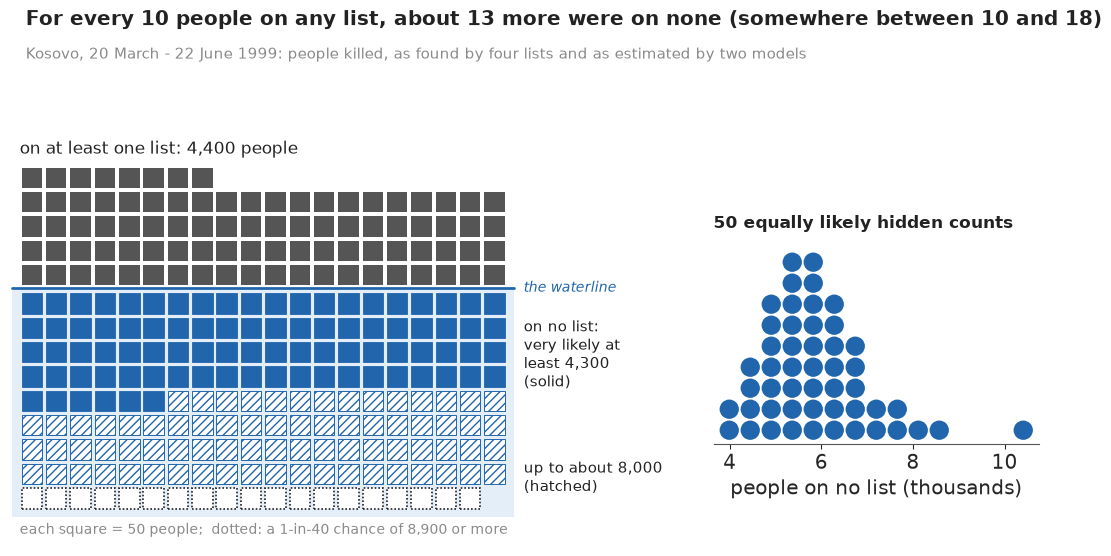

In [2]:
HEADLINE = display(Markdown("*The headline figure is drawn in part G from the fits below and "
                            "appears here once the notebook has run.*"), display_id=True)

## The setting

Between March and June 1999 Yugoslav forces and the Kosovo Liberation Army fought in Kosovo,
NATO bombed, and most of the Kosovar Albanian population fled. Afterwards several organisations
recorded the dead: forensic teams exhuming graves (EXH), the American Bar Association's Central
and East European Law Initiative interviewing refugees (ABA), the OSCE's human-rights mission
(OSCE) and Human Rights Watch (HRW). Each list is a record of what one organisation could reach.
Ball, Betts, Scheuren, Dudukovich & Asher (2002) matched the four lists name by name - about
10,000 reports came down to 4,400 distinct people - and asked the question this notebook asks:
how many people were killed whom nobody recorded? Their answer, 10,356 (95% interval
9,002-12,122), was presented as evidence at the International Criminal Tribunal for the former
Yugoslavia in the trial of Slobodan Milosevic, together with the timing of the killings and the
refugee flows, which did not follow the pattern of NATO bombing or KLA activity.

The method is **multiple-systems estimation** (MSE), the human-rights name for what ecologists
call capture-recapture (E28 counted hares with it). Every person has a capture history, a 0/1
string saying which lists name them. With $K$ lists there are $2^K - 1$ observable histories and
one cell, "on no list", that is empty by construction. Fienberg (1972) showed how a log-linear
model of the observed cells predicts that missing cell. The prediction rests entirely on how the
lists depend on each other, and Lum, Price & Banks (2013) explain why that is the central
difficulty in human-rights work: lists are made by organisations that talk to each other, reach
the same villages and miss the same people. Two Bayesian answers stand out. Madigan & York
(1997) average over the graphical models that say which lists depend on which; Manrique-Vallier
(2016) lets people fall into hidden classes with their own visibility, which is how the Human
Rights Data Analysis Group now works (the LCMCR package). Silverman (2020) compared both on the
UK's modern-slavery lists and got answers a factor of two apart; Chan, Silverman & Vincent (2021)
studied what goes wrong when some lists never overlap at all.

We work through both datasets, Kosovo first, because it is the cleaner case: four lists, every
combination seen, and a published answer to compare with.

| part | question | tool |
|---|---|---|
| A | What do the lists look like? | the 15 observed histories, list sizes and overlaps |
| B | Why does overlap measure the unseen, and how does it fail? | Lincoln-Petersen; a simulation with dependent lists; the six two-list estimates |
| C | How do log-linear models fill the empty cell? | independence, pairwise and three-way models; a regularised horseshoe; cell-by-cell checks; which prior family |
| D | What if people differ in how visible they are? | the latent-class model, summed over classes; label switching |
| E | Which assumption should we believe? | averaging over 113 hierarchical log-linear models; stacking with exact leave-one-cell-out; the headline mixture; "what you would have to believe" |
| F | Does it work with six sparse lists? | UK 2013: the Home Office model, horseshoe against latent class, the general-public list |
| G | How do we explain it to everyone? | the iceberg, a HOP GIF, a dotplot column, a 100-world swarm; the statistician's plot for contrast |

## A · Four lists and the people on none

The file holds one row per observed capture history for five datasets, with the list names in
the order of the history string.

In [3]:
data.describe("e109_mse_lists")
MSE = data.load("e109_mse_lists")
print(MSE.groupby("dataset").agg(lists=("lists", "first"), histories=("count", "size"),
                                 people=("count", "sum")).to_string())


def table(ds, drop=(), merge=None):
    """The capture-history table of one dataset: list names, all 2^K - 1 non-empty histories (rows of 0/1),
    their counts (zero where nobody had that history) and the history strings. `drop` removes lists,
    `merge=(a, b, new)` merges two lists into one."""
    g = MSE[MSE.dataset == ds]
    lists = g.lists.iloc[0].split("|")
    d = pd.DataFrame([list(map(int, h)) for h in g.history], columns=lists)
    d["n"] = g["count"].to_numpy()
    keep = [l for l in lists if l not in drop]
    if merge:
        a, b, new = merge
        d[new] = np.maximum(d[a], d[b])
        keep = [new if l == a else l for l in keep if l != b]
    cnt = d.groupby(keep)["n"].sum()
    K = len(keep)
    H = np.array(list(it.product([0, 1], repeat=K)))[1:]
    n = cnt.reindex([tuple(h) for h in H]).fillna(0).astype(int).to_numpy()
    return keep, H, n, ["".join(map(str, h)) for h in H]


LISTS, H, n, KEY = table("kosovo")
NOBS = int(n.sum())
K = len(LISTS)
sizes = {l: int(n[H[:, k] == 1].sum()) for k, l in enumerate(LISTS)}
print(f"\nKosovo: {NOBS:,} people on {K} lists; list sizes {sizes}")
print("people on exactly 1 / 2 / 3 / 4 lists:", [int(n[H.sum(1) == j].sum()) for j in range(1, 5)])

e109_mse_lists: One row per OBSERVED capture history (the all-zero history is never observed): dataset (kosovo, uk2013, netherlands, new_orleans, western_us), lists (list names joined by '|', in history order), history (0/1 string, one character per list; read as a string), count (people with that history). Kosovo 15 rows / 4,400 people; UK 25 / 2,744; Netherlands 24 / 8,234; New Orleans 19 / 185; Western 13 / 345. Histories with zero people are omitted.
  source: Capture-history counts from two CRAN packages (GPL >= 2), the data from published reports. Kosovo: LCMCR 0.4.14 (Manrique-Vallier) `kosovo_aggregate`, 4,400 killings in Kosovo, 20 March - 22 June 1999, on four lists - EXH (exhumations), ABA (American Bar Association / CEELI interviews), OSCE, HRW (Human Rights Watch) - analysed by Ball, Betts, Scheuren, Dudukovich & Asher (2002, AAAS/ABA-CEELI report to the ICTY). UK 2013: SparseMSE 2.0.1 (Chan, Silverman & Vincent) `UKdat`, 2,744 potential victims of trafficking in the Natio

Four lists of different sizes: the exhumations name about 1,900 people, the OSCE about 1,800,
the ABA interviews about 1,500 and Human Rights Watch about 700. Most people, about 3,200 of the
4,400, appear on one list only, and only 27 appear on all four. The chart shows every
history, largest first, with the dots below saying which lists it involves. On the far left is
the column every MSE analysis is about: people on no list, whose height is unknown.

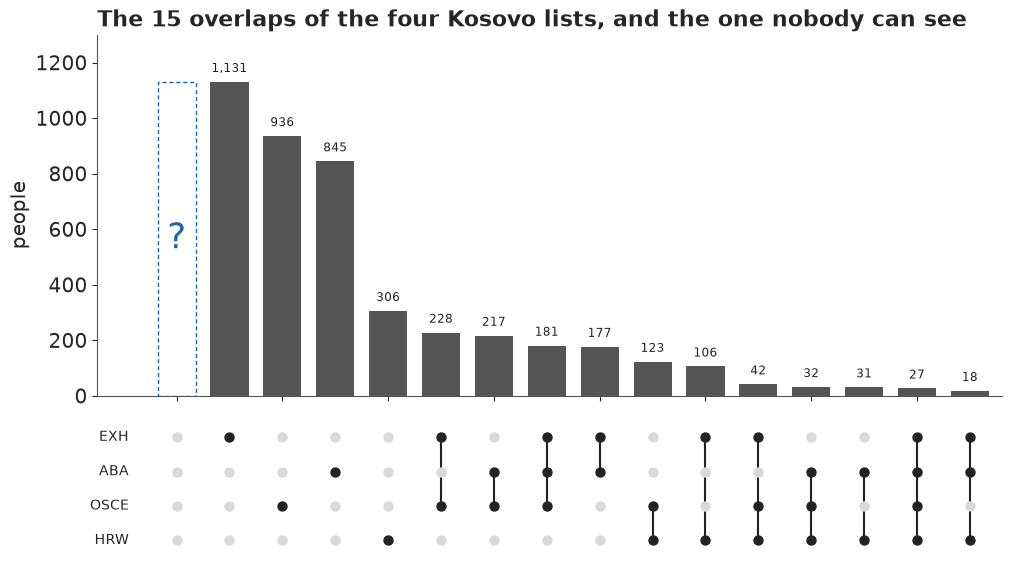

In [4]:
order_c = np.argsort(-n)


def overlap_chart(ax_bar, ax_dot, hidden=None, title=""):
    """UpSet-style chart of the observed histories, with the never-observed history in column 0:
    a question mark, or a 20-dot quantile column of the hidden count."""
    xs = np.arange(len(n) + 1)
    ax_bar.bar(xs[1:], n[order_c], color=GREY, width=0.72)
    for x, v in zip(xs[1:], n[order_c]):
        ax_bar.text(x, v + 25, f"{v:,}", ha="center", va="bottom", fontsize=8.5, color=INK)
    if hidden is None:
        ax_bar.bar([0], [n.max()], color="none", edgecolor=HI, ls=(0, (3, 2)), width=0.72)
        ax_bar.text(0, n.max() / 2, "?", ha="center", va="center", fontsize=26, color=HI)
        top = n.max() * 1.15
    else:
        q = np.quantile(hidden, (np.arange(20) + 0.5) / 20)
        ax_bar.scatter(np.zeros(20), q, s=26, color=HI, zorder=3, clip_on=False)
        ax_bar.text(0.55, q.max(), "on no list:\n20 equally likely\nvalues", ha="left", va="top",
                    fontsize=9.5, color=HI)
        top = q.max() * 1.05
    ax_bar.set_ylim(0, top)
    ax_bar.set_ylabel("people")
    ax_bar.set_title(title, loc="left")
    for j, l in enumerate(LISTS):
        for x in xs:
            h = np.zeros(K, int) if x == 0 else H[order_c[x - 1]]
            ax_dot.scatter(x, K - 1 - j, s=42, color=INK if h[j] else LIGHT, zorder=3)
        ax_dot.text(-0.9, K - 1 - j, l, ha="right", va="center", fontsize=10)
    for x in xs[1:]:
        on = np.where(H[order_c[x - 1]] == 1)[0]
        ax_dot.plot([x, x], [K - 1 - on.max(), K - 1 - on.min()], color=INK, lw=1.5, zorder=2)
    ax_dot.set_xlim(-1.5, len(n) + 0.6)
    ax_dot.set_ylim(-0.6, K - 0.4)
    ax_dot.axis("off")


fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5.6), sharex=True, gridspec_kw={"height_ratios": [3, 1.2]})
overlap_chart(a1, a2, title="The 15 overlaps of the four Kosovo lists, and the one nobody can see")
a1.set_xlim(-1.5, len(n) + 0.6);

## B · Two lists, and how they mislead

### Lincoln-Petersen

Take two lists, A and B, of sizes $n_A$ and $n_B$, and let $m$ people be on both. If the lists
were drawn independently from a population of $N$, the chance of being on A is $n_A/N$ whether
or not one is on B, so the share of B's people who are also on A, $m/n_B$, estimates $n_A/N$:

$$\hat N = \frac{n_A\, n_B}{m}.$$

This is the Lincoln-Petersen estimator. Its weak point is the word *independently*. If some
people are easy for every organisation to find - a village near a road, a family that went to
the refugee camps early - the lists overlap more than chance, $m$ is too big, and $\hat N$ is too
small. If the lists divide the territory between them, they overlap less than chance and
$\hat N$ is too big. The simulation below keeps the two list sizes the same in all three worlds
(30% and 40% of 10,000 people) and changes only how they depend on each other.

independent                  median estimate  10,001  (89%: 9,710-10,310)  truth 10,000
same people easy to find     median estimate   7,501  (89%: 7,334-7,670)  truth 10,000


lists split the territory    median estimate  15,008  (89%: 14,370-15,618)  truth 10,000


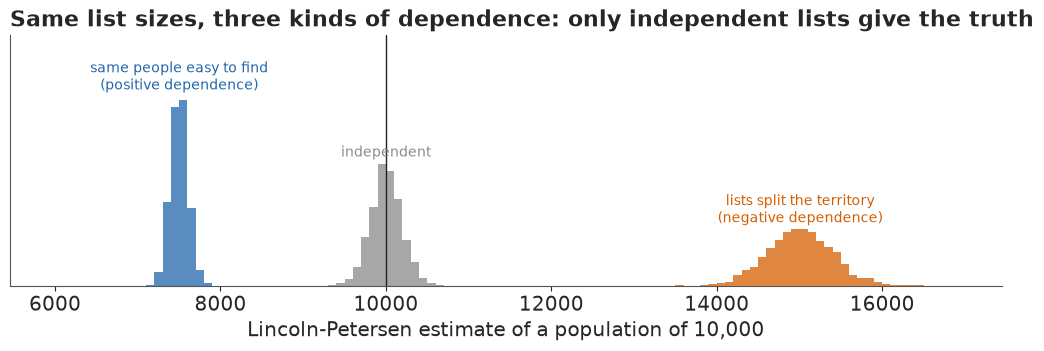

In [5]:
N_TOY, reps = 10_000, 2000
worlds = {  # (share of people, P(on A), P(on B)) for two groups; same list sizes in every world
    "independent": [(1.0, 0.30, 0.40)],
    "same people easy to find\n(positive dependence)": [(0.5, 0.50, 0.60), (0.5, 0.10, 0.20)],
    "lists split the territory\n(negative dependence)": [(0.5, 0.50, 0.20), (0.5, 0.10, 0.60)],
}
toy = {}
for w, groups in worlds.items():
    est = np.zeros(reps)
    for r in range(reps):
        nA = nB = m = 0
        for share, pa, pb in groups:
            size = int(share * N_TOY)
            a = rng.random(size) < pa
            b = rng.random(size) < pb
            nA, nB, m = nA + a.sum(), nB + b.sum(), m + (a & b).sum()
        est[r] = nA * nB / m
    toy[w] = est
    print(f"{w.splitlines()[0]:28s} median estimate {np.median(est):7,.0f}  (89%: "
          f"{np.quantile(est, 0.055):,.0f}-{np.quantile(est, 0.945):,.0f})  truth {N_TOY:,}")

fig, ax = plt.subplots(figsize=(10, 3.4))
for (w, est), col in zip(toy.items(), [MUTED, HI, LO]):
    ax.hist(est, bins=np.arange(6000, 17000, 100), color=col, alpha=0.75, label=w)
    peak = np.histogram(est, bins=np.arange(6000, 17000, 100))[0].max()
    ax.text(np.median(est), peak * 1.03, w, ha="center", va="bottom", fontsize=10, color=col)
ax.axvline(N_TOY, color=INK, lw=1)
ax.set_xlabel("Lincoln-Petersen estimate of a population of 10,000")
ax.set_yticks([])
ax.set_ylim(0, max(np.histogram(e, bins=np.arange(6000, 17000, 100))[0].max() for e in toy.values()) * 1.35)
ax.set_title("Same list sizes, three kinds of dependence: only independent lists give the truth",
             loc="left");

With independent lists the estimate centres on the truth. When the same people are easy for
both lists to find, it centres near 7,500, a quarter too low, and no amount of data fixes it:
the bias is in the assumption. When the lists split the territory it centres near 15,000. The
lists' sizes are identical in all three worlds; only their dependence differs, and two lists
alone cannot tell us which world we are in.

### The six two-list estimates for Kosovo

Ball et al. (2002, appendix 2) printed the Lincoln-Petersen estimate for each of the six pairs of
Kosovo lists. Recomputing them is also a check that the table we have is the one they used.

In [6]:
BALL_LP = {("EXH", "ABA"): 7245, ("ABA", "HRW"): 9689, ("ABA", "OSCE"): 5970, ("EXH", "HRW"): 6777,
           ("EXH", "OSCE"): 7135, ("OSCE", "HRW"): 5461}
rows = []
for a, b in it.combinations(range(K), 2):
    nA, nB = n[H[:, a] == 1].sum(), n[H[:, b] == 1].sum()
    m = n[(H[:, a] == 1) & (H[:, b] == 1)].sum()
    rows.append(dict(pair=f"{LISTS[a]}-{LISTS[b]}", n_A=nA, n_B=nB, both=m, estimate=round(nA * nB / m),
                     ball_2002=BALL_LP[(LISTS[a], LISTS[b])]))
print(pd.DataFrame(rows).to_string(index=False))

    pair  n_A  n_B  both  estimate  ball_2002
 EXH-ABA 1910 1528   403      7242       7245
EXH-OSCE 1910 1786   478      7137       7135
 EXH-HRW 1910  685   193      6779       6777
ABA-OSCE 1528 1786   457      5972       5970
 ABA-HRW 1528  685   108      9691       9689
OSCE-HRW 1786  685   224      5462       5461


Every estimate agrees with the published table to within 3 people, so the CRAN table is the
one the report used. The six estimates run from about 5,500 to 9,700, and all of them are below
the 10,356 that Ball et al. finally reported - most of them far below. That pattern is what
positive dependence looks like: each pair of lists overlaps more than independent lists would,
so each pair concludes that few people were missed. Ball et al. read it the same way ("a great
deal of positive dependence between the lists"). With four lists we can do better than any pair,
because some of that dependence shows up in the other lists.

## C · Log-linear models of the incomplete table

### The model

Write $n_h$ for the number of people with history $h \in \{0,1\}^4$, and let the counts be
Poisson. A log-linear model writes the log of each cell's expected count as a sum of terms:

$$\log \mu_h = \lambda_0 + \sum_k \lambda_k h_k + \sum_{k<l} \lambda_{kl} h_k h_l
  + \sum_{k<l<m} \lambda_{klm} h_k h_l h_m .$$

The empty history $h = 0000$ switches every term off but $\lambda_0$, so the expected number of
people on no list is $e^{\lambda_0}$, and the total is $N = n_{\text{obs}} + n_{0000}$ with
$n_{0000} \sim \text{Poisson}(e^{\lambda_0})$. The main effects $\lambda_k$ are the log odds of
being on list $k$. The pair terms $\lambda_{kl}$ are log odds ratios: $e^{\lambda_{kl}} = 2$ means
being on list $k$ doubles the odds of being on list $l$. Without interactions the model is
independence, and every interaction is an assumed dependence. The four-way term cannot be in the
model at all: it would need the missing cell to estimate it, which is the untestable assumption
at the heart of MSE. Everything in this part assumes it is zero.

Two lists give three observed cells, enough for $\lambda_0$, $\lambda_A$ and $\lambda_B$ and
nothing more, which is why Lincoln-Petersen has to assume independence. Four lists give 15
cells: room for all 6 pair terms and all 4 three-way terms (15 parameters, a saturated fit). The
question is how many of them to believe.

### Classical fits, for reference

Maximum likelihood with no prior is three lines of NumPy, and gives three quite different
answers depending on which terms go in.

In [7]:
def design(Hm, terms):
    cols = [np.ones(len(Hm))] + [Hm[:, k] for k in range(Hm.shape[1])]
    return np.column_stack(cols + [np.prod(Hm[:, list(t)], axis=1) for t in terms]).astype(float)


def fit_mle(Hm, nm, terms):
    """Poisson log-linear maximum likelihood: returns the coefficients, the hidden count exp(l0) and the deviance."""
    X = design(Hm, terms)
    b0 = np.zeros(X.shape[1])
    b0[0] = np.log(nm.mean())
    r = minimize(lambda b: np.sum(np.exp(X @ b) - nm * (X @ b)), b0, jac=lambda b: X.T @ (np.exp(X @ b) - nm),
                 method="L-BFGS-B", options={"maxiter": 5000})
    mu = np.exp(X @ r.x)
    dev = 2 * np.sum(np.where(nm > 0, nm * np.log(np.maximum(nm, 1) / mu), 0) - (nm - mu))
    return r.x, np.exp(r.x[0]), dev, len(nm) - X.shape[1]


PAIRS = list(it.combinations(range(K), 2))
TRIPLES = list(it.combinations(range(K), 3))
for label, terms in [("independence", []), ("all pairs", PAIRS), ("all pairs + all triples", PAIRS + TRIPLES)]:
    b, N0, dev, df = fit_mle(H, n, terms)
    print(f"MLE {label:24s}: total {NOBS + N0:7,.0f}   deviance {dev:6.1f} on {df:2d} df")

MLE independence            : total   7,395   deviance  245.9 on 10 df
MLE all pairs               : total  14,410   deviance   39.8 on  4 df
MLE all pairs + all triples : total  16,951   deviance    0.0 on  0 df


Independence says about 7,400 and fits terribly (a deviance of about 250 on 10 degrees of
freedom, where a model that fits would give about 10). All pairs says about 14,400 and still
fits badly. Adding the three-way terms fits the 15 cells exactly and says 17,000. The saturated
model is not wrong to fit perfectly - it has as many parameters as cells - but that leaves
nothing over to check its estimate of the hidden cell against. We will come back to it.

### Priors

The Bayesian version needs a prior for each kind of term. For $\lambda_0$ we centre the hidden
count on the number listed with a wide spread, $\lambda_0 \sim N(\log 4400, 1.5)$, which puts 89%
of the prior between about 400 and 50,000 hidden people. Centring on the observed total uses the
data once more, in the empirical-Bayes way. For the main effects, $\lambda_k \sim N(-1, 1.5)$: a
list catches somewhere between a few percent and most of the people. Part C's Failure 2 widens
both of these priors and shows when they matter. The interactions get a **horseshoe** (Carvalho, Polson & Scott
2010): each term has its own scale $c_j \sim \text{HalfCauchy}(1)$ times a global
$\tau \sim \text{HalfNormal}(0.5)$ for the pairs and $\text{HalfNormal}(0.25)$ for the triples.
The horseshoe says that most dependencies are probably small and a few may be large, which is how
analysts of these lists describe them, and it replaces the stepwise search over models that
classical MSE uses with shrinkage.

The code builds all the log-linear models from one function. `orders=()` is independence;
`slab` turns the horseshoe into the regularised version we will need in a moment; `ridge`
swaps the horseshoe for a plain normal prior, for a comparison; `fix_pair` and `masked` are for
the sensitivity and the leave-one-out refits later on.

prior: hidden count 5.5/50/94.5%: [  380.  4410. 49470.]
prior: total listed 5.5/50/94.5%: [   1480.   30090. 1168620.] (observed 4,400)


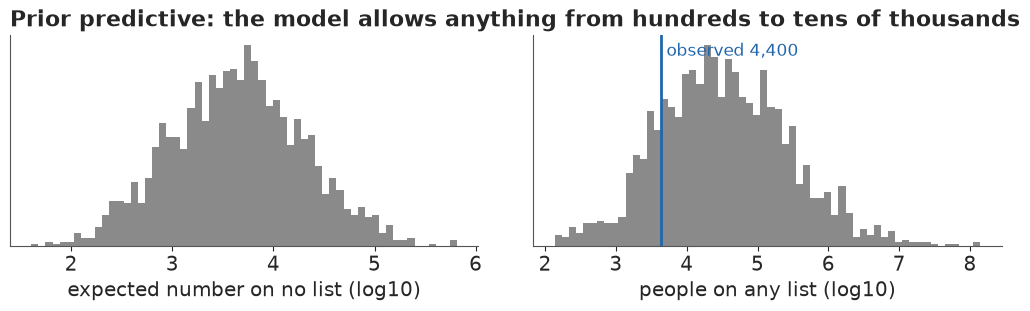

In [8]:
def loglinear(lists, Hm, nm, *, orders=(), tau_sd=(), slab=2.0, ridge=None, l0_sd=1.5, lk_sd=1.5, fix_pair=None,
              masked=False):
    """Poisson log-linear MSE. exp(l0) is the expected number on no list. Interactions of each order get a
    (regularised, when `slab` is set) horseshoe written non-centred, or N(0, ridge^2) when `ridge` is set."""
    Kl = len(lists)
    with pm.Model(coords={"cell": ["".join(map(str, h)) for h in Hm], "list": lists}) as m:
        l0 = pm.Normal("l0", np.log(nm.sum()), l0_sd)
        lk = pm.Normal("lk", -1.0, lk_sd, dims="list")
        eta = l0 + pt.dot(Hm.astype(float), lk)
        for order, tsd in zip(orders, tau_sd):
            terms = list(it.combinations(range(Kl), order))
            X = np.column_stack([np.prod(Hm[:, list(t)], axis=1) for t in terms]).astype(float)
            dim = f"term{order}"
            m.add_coord(dim, ["-".join(lists[i] for i in t) for t in terms])
            if ridge is not None:
                scale = ridge
            else:
                tau = pm.HalfNormal(f"tau{order}", tsd)
                scale = tau * pm.HalfCauchy(f"c{order}", 1.0, dims=dim)
                if slab is not None:  # Piironen & Vehtari (2017): large terms see a Normal(0, slab) instead
                    scale = slab * scale / pt.sqrt(slab**2 + scale**2)
            lam = scale * pm.Normal(f"z{order}", 0.0, 1.0, dims=dim)
            if fix_pair is not None and order == 2:  # one dependence held at an assumed value
                lam = pt.set_subtensor(lam[terms.index(fix_pair)], pm.Data("fixed", 0.0))
            lam = pm.Deterministic(f"lam{order}", lam, dims=dim)
            eta = eta + pt.dot(X, lam)
        pm.Deterministic("N0_mean", pt.exp(l0))
        likelihood(pm.Deterministic("mu", pt.exp(eta), dims="cell"), nm, masked)
    return m


def likelihood(mu, nm, masked):
    if masked:  # exact leave-one-cell-out: a 0/1 mask swapped into one compiled model
        mask = pm.Data("mask", np.ones(len(nm)), dims="cell")
        pm.Potential("ll", pt.sum(mask * pm.logp(pm.Poisson.dist(mu), nm)))
    else:
        pm.Poisson("n", mu, observed=nm, dims="cell")


m_prior = loglinear(LISTS, H, n, orders=(2, 3), tau_sd=(0.5, 0.25))
with m_prior:
    prior = pm.sample_prior_predictive(2000, random_seed=RANDOM_SEED)
hid_prior = prior.prior["N0_mean"].to_numpy().ravel()
obs_prior = prior.prior_predictive["n"].to_numpy().reshape(-1, len(n)).sum(1)
print("prior: hidden count 5.5/50/94.5%:", np.round(np.quantile(hid_prior, [0.055, 0.5, 0.945]), -1))
print("prior: total listed 5.5/50/94.5%:", np.round(np.quantile(obs_prior, [0.055, 0.5, 0.945]), -1),
      f"(observed {NOBS:,})")
fig, axs = plt.subplots(1, 2, figsize=(10, 3))
for ax, v, lab in [(axs[0], hid_prior, "expected number on no list"), (axs[1], obs_prior, "people on any list")]:
    ax.hist(np.log10(np.maximum(v, 1)), bins=60, color=MUTED)
    ax.set_xlabel(f"{lab} (log10)")
    ax.set_yticks([])
axs[1].axvline(np.log10(NOBS), color=HI, lw=2)
axs[1].text(np.log10(NOBS), axs[1].get_ylim()[1] * 0.9, " observed 4,400", color=HI)
axs[0].set_title("Prior predictive: the model allows anything from hundreds to tens of thousands",
                 loc="left");

The prior allows hidden counts from about 400 to 50,000 (89%), and listed totals from about
1,500 to well over a million. The observed 4,400 sits in the lower part of that range (the prior
median is about 30,000, because the main effects allow lists that catch most people) but well
inside it. The prior is wide and rules out nothing a reader could believe before seeing the
overlaps; the 15 cells will do the work.

### Failure 1: the horseshoe's funnel

We fit the pairwise model first with the textbook horseshoe and nutpie's defaults, then change
one thing at a time: a higher `target_accept`, and the regularised horseshoe described below.

In [9]:
def fit(m, ta=0.8, **kw):
    global LAST_MODEL
    LAST_MODEL = m  # summarise() needs it for the log-likelihood
    t0 = time.time()
    with m:
        idata = pm.sample(random_seed=RANDOM_SEED, progressbar=False, target_accept=ta, **kw)
    return idata, time.time() - t0


def worst_rhat(idata, skip=()):
    r = {v: float(az.rhat(idata, var_names=[v])[v].max()) for v in idata.posterior.data_vars if v not in skip}
    v = max(r, key=r.get)
    return f"{r[v]:.3f} ({v})"


for lab, slab, ta in [("plain horseshoe", None, 0.8), ("plain horseshoe", None, 0.99),
                      ("regularised horseshoe", 2.0, 0.8)]:
    idata_hs, sec = fit(loglinear(LISTS, H, n, orders=(2,), tau_sd=(0.5,), slab=slab), ta)
    print(f"{lab:22s} target_accept {ta}: {sec:.0f} s, sampled parameters "
          f"{sum(idata_hs.posterior[v][0, 0].size for v in ('l0', 'lk', 'tau2', 'c2', 'z2'))}, divergences "
          f"{int(idata_hs.sample_stats['diverging'].sum())}, worst r_hat {worst_rhat(idata_hs)}")
del idata_hs

plain horseshoe        target_accept 0.8: 4 s, sampled parameters 18, divergences 92, worst r_hat 1.013 (c2)


plain horseshoe        target_accept 0.99: 3 s, sampled parameters 18, divergences 9, worst r_hat 1.003 (z2)


regularised horseshoe  target_accept 0.8: 2 s, sampled parameters 18, divergences 0, worst r_hat 1.004 (c2)


About ninety divergences, from a model with eighteen sampled parameters (the intercept, four main
effects, the global scale, and six local scales and six standardised terms for the pairs). The
horseshoe's half-Cauchy scales let a term's prior sd reach almost zero, where its coefficient
must be almost exactly zero, and also very large values; NUTS cannot find one step size for both
ends of that funnel. Raising `target_accept` to 0.99 makes the steps smaller and cuts the count
to about ten, but does not remove them. What does is the **regularised horseshoe** of Piironen &
Vehtari (2017): the scale is passed through
$s \mapsto \text{slab}\cdot s/\sqrt{\text{slab}^2 + s^2}$, so very large terms see a
$N(0, 2^2)$ "slab" rather than a Cauchy tail. With it the default `target_accept` already gives
no divergences. A log odds ratio of 2 is a factor of 7 in the odds, already a strong dependence,
so the slab costs nothing we believe. We keep `target_accept=0.99` for the models with interaction
terms below anyway, as cheap insurance on these small models.

### Three models, fitted

We fit independence (M0), pairs (M1) and pairs plus triples (M1b), all with the regularised
horseshoe, keep the posterior of the hidden count and the expected counts of every cell, and
compute PSIS leave-one-out for later.

In [10]:
def summarise(name, idata, nm, sec, skip=()):
    """Diagnostics, draws of the total N (observed + Poisson hidden count), cell means and PSIS-LOO."""
    nobs = int(nm.sum())
    N = nobs + rng.poisson(idata.posterior["N0_mean"].to_numpy().ravel())
    mu = idata.posterior["mu"].to_numpy().reshape(-1, len(nm))
    yrep = rng.poisson(mu)
    lo, hi = np.quantile(yrep, [0.055, 0.945], axis=0)
    miss = [(KEYS[i], int(nm[i]), int(lo[i]), int(hi[i])) for i in range(len(nm)) if not lo[i] <= nm[i] <= hi[i]]
    q = np.quantile(N, [0.055, 0.5, 0.945])
    print(f"{name}: {sec:.0f} s, tune {idata.posterior.attrs.get('tuning_steps')}, divergences "
          f"{int(idata.sample_stats['diverging'].sum())}, r_hat(N0) "
          f"{float(az.rhat(idata, var_names=['N0_mean'])['N0_mean']):.3f}, worst r_hat {worst_rhat(idata, skip)}, "
          f"ESS(N0) {float(az.ess(idata, var_names=['N0_mean'])['N0_mean']):.0f}")
    print(f"   total N: {q[1]:,.0f}  (89%: {q[0]:,.0f}-{q[2]:,.0f});  cells outside their 89% predictive "
          f"range: {len(miss)} of {len(nm)}  {miss if len(miss) <= 5 else ''}")
    out = dict(N=N, yrep=yrep)
    if "n" in idata.observed_data:
        pm.compute_log_likelihood(idata, model=LAST_MODEL, progressbar=False)
        loo = az.loo(idata, pointwise=True)
        out["k_bad"] = int((loo.pareto_k > 0.7).sum())
        print(f"   PSIS-LOO: {out['k_bad']} of {len(nm)} cells with Pareto k > 0.7")
    return out


KEYS = KEY
KOS = {}
SPEC = {  # name: (model builder, target_accept)
    "M0 independence": (lambda **kw: loglinear(LISTS, H, n, **kw), 0.8),
    "M1 pairs": (lambda **kw: loglinear(LISTS, H, n, orders=(2,), tau_sd=(0.5,), **kw), 0.99),
    "M1b pairs + triples": (lambda **kw: loglinear(LISTS, H, n, orders=(2, 3), tau_sd=(0.5, 0.25), **kw), 0.99),
}
t0 = time.time()
for name, (mk, ta) in SPEC.items():
    idata, sec = fit(mk(), ta)
    KOS[name] = summarise(name, idata, n, sec)
    if name.startswith("M1b"):
        lam2 = idata.posterior["lam2"]
        lam3 = idata.posterior["lam3"]
        ABA_HRW_FREE = np.exp(lam2.sel(term2="ABA-HRW").to_numpy().ravel())
        print("   pair terms as odds multipliers (posterior median):",
              dict(zip(lam2.term2.values, np.round(np.exp(lam2.median(("chain", "draw")).to_numpy()), 2))))
        print("   three-way terms (posterior median):",
              dict(zip(lam3.term3.values, np.round(lam3.median(("chain", "draw")).to_numpy(), 2))))
    del idata
TIMES["log-linear fits"] = time.time() - t0

M0 independence: 1 s, tune 400, divergences 0, r_hat(N0) 1.001, worst r_hat 1.002 (mu), ESS(N0) 1346
   total N: 7,396  (89%: 7,193-7,604);  cells outside their 89% predictive range: 10 of 15  
   PSIS-LOO: 7 of 15 cells with Pareto k > 0.7


M1 pairs: 3 s, tune 400, divergences 0, r_hat(N0) 1.000, worst r_hat 1.003 (z2), ESS(N0) 2517
   total N: 13,658  (89%: 12,264-15,341);  cells outside their 89% predictive range: 5 of 15  [('0110', 217, 219, 289), ('1001', 106, 66, 105), ('1011', 42, 43, 73), ('1100', 177, 180, 243), ('1110', 181, 118, 167)]
   PSIS-LOO: 11 of 15 cells with Pareto k > 0.7


M1b pairs + triples: 4 s, tune 400, divergences 0, r_hat(N0) 1.004, worst r_hat 1.005 (lk), ESS(N0) 757
   total N: 9,282  (89%: 8,281-10,537);  cells outside their 89% predictive range: 0 of 15  []
   PSIS-LOO: 14 of 15 cells with Pareto k > 0.7
   pair terms as odds multipliers (posterior median): {'EXH-ABA': np.float64(0.97), 'EXH-OSCE': np.float64(1.03), 'EXH-HRW': np.float64(1.48), 'ABA-OSCE': np.float64(1.37), 'ABA-HRW': np.float64(0.81), 'OSCE-HRW': np.float64(2.13)}
   three-way terms (posterior median): {'EXH-ABA-OSCE': np.float64(1.25), 'EXH-ABA-HRW': np.float64(0.01), 'EXH-OSCE-HRW': np.float64(-0.03), 'ABA-OSCE-HRW': np.float64(0.06)}


All three sample cleanly now (no divergences, r_hat at most 1.01). Their answers do not agree.
Independence (M0) says about 7,400 people were killed in all and misses 10 of the 15 observed
cells: it is the Lincoln-Petersen assumption applied to four lists, and the lists plainly are not
independent. The pairwise model (M1) says about 13,600 and misses 5 cells. The model with
three-way terms (M1b) reproduces all 15 cells and says about 9,300 (89%: 8,300-10,500); with 15
coefficients for 15 cells it is saturated, so fitting every cell is expected of it and is no
evidence in its favour. PSIS leave-one-out is unreliable for about half the cells of M0 and for
most of M1 and M1b (the Pareto k counts are printed); part E comes back to that.

Where M1 fails is informative. The figure shows each cell's observed count against the 89%
range each model predicts for it.

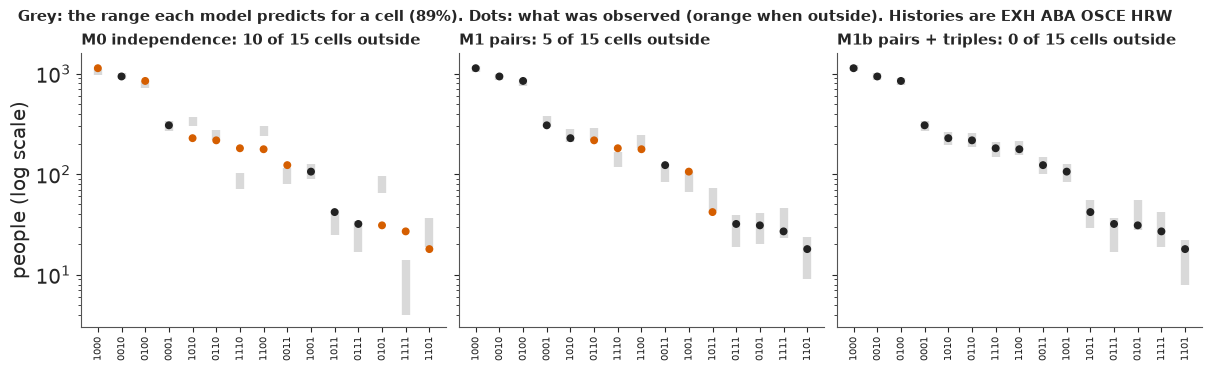

In [11]:
def ppc_panel(ax, out, nm, keys, title, log=True):
    order = np.argsort(-nm)
    lo, mid, hi = np.quantile(out["yrep"], [0.055, 0.5, 0.945], axis=0)
    x = np.arange(len(nm))
    inside = (lo <= nm) & (nm <= hi)
    ax.vlines(x, lo[order], hi[order], color=LIGHT, lw=6)
    ax.scatter(x, nm[order], s=22, color=np.where(inside[order], INK, LO), zorder=3)
    ax.set_xticks(x, [keys[i] for i in order], rotation=90, fontsize=7.5)
    if log:
        ax.set_yscale("log")
    ax.set_title(f"{title}: {int((~inside).sum())} of {len(nm)} cells outside", loc="left", fontsize=11)


fig, axs = plt.subplots(1, 3, figsize=(12, 3.6), sharey=True)
for ax, (name, out) in zip(axs, KOS.items()):
    ppc_panel(ax, out, n, KEY, name)
axs[0].set_ylabel("people (log scale)")
fig.suptitle("Grey: the range each model predicts for a cell (89%). Dots: what was observed "
             "(orange when outside). Histories are EXH ABA OSCE HRW", x=0.01, ha="left", fontsize=11);

The pairwise model's clearest miss is history 1110, the 181 people found by the exhumations, the
ABA interviews and the OSCE but not by Human Rights Watch: it predicts 118 to 167. Those
three lists share more people than their pairwise dependencies explain, a **three-way
dependence**, and M1b's posterior puts a large positive term on exactly that triple (its median
is printed above, a log odds ratio above 1). Once it is in, every cell fits.

The fitted pair terms are also printed as odds multipliers, each given the other lists and the
three-way term. OSCE-HRW overlap about twice as often as chance, EXH-HRW and ABA-OSCE about one
and a half times, and two pairs sit at chance. ABA-HRW comes out at about 0.8, slightly *less*
than chance. We will lean on that pair in part E.

### Failure 2: the prior family decides the answer

The saturated maximum-likelihood fit said 17,000; M1b, the same terms with priors, says about
9,300. Both reproduce the 15 cells, so the difference must come from the priors. To find which
part of the prior matters, we refit the same ten interaction terms under plain normal priors of
three widths, and the horseshoe with three of its other dials turned: the triples' global scale
raised from 0.25 to 1, the sd of $\lambda_0$ doubled to 3, and the sd of the main effects
$\lambda_k$ raised from 1.5 to 5. The last dial is also tried under the two flattest normal priors.
The nearly flat fits mix slowly along the ridge where $\lambda_0$ and the main effects trade off, so
every fit here runs 1,500 warm-up steps and 2,000 draws per chain (a few seconds each), and we
print the r_hat and ESS of $\lambda_0$.

In [12]:
t0 = time.time()
PRIORS = {"normal, sd 1": dict(ridge=1.0), "normal, sd 3": dict(ridge=3.0), "normal, sd 10": dict(ridge=10.0),
          "normal, sd 3, main sd 5": dict(ridge=3.0, lk_sd=5.0), "normal, sd 10, main sd 5": dict(ridge=10.0, lk_sd=5.0),
          "horseshoe, triples' scale 1": dict(tau_sd=(0.5, 1.0)), "horseshoe, sd of l0 3": dict(l0_sd=3.0),
          "horseshoe, main sd 5": dict(lk_sd=5.0)}
j_ah = PAIRS.index((LISTS.index("ABA"), LISTS.index("HRW")))
b_sat = fit_mle(H, n, PAIRS + TRIPLES)[0]
print("saturated MLE, pair terms as odds multipliers:",
      {f"{LISTS[i]}-{LISTS[j]}": round(float(np.exp(v)), 2) for (i, j), v in zip(PAIRS, b_sat[1 + K:1 + K + len(PAIRS)])})
print(f"saturated MLE, EXH-ABA-OSCE three-way term: {b_sat[1 + K + len(PAIRS)]:.2f}")
for lab, kw in PRIORS.items():
    idata, sec = fit(loglinear(LISTS, H, n, orders=(2, 3), **{"tau_sd": (0.5, 0.25), **kw}), 0.99,
                     tune=1500, draws=2000)
    Nd = NOBS + np.random.default_rng(3).poisson(idata.posterior["N0_mean"].to_numpy().ravel())
    q = np.quantile(Nd, [0.055, 0.5, 0.945])
    ah = idata.posterior["lam2"].to_numpy().reshape(-1, len(PAIRS))[:, j_ah]
    l0d = idata.posterior["l0"].to_numpy().ravel()
    print(f"{lab:27s}: div {int(idata.sample_stats['diverging'].sum())}, r_hat(l0) "
          f"{float(az.rhat(idata, var_names=['l0'])['l0']):.3f}, ESS(l0) {float(az.ess(idata, var_names=['l0'])['l0']):4.0f};"
          f"  N {q[1]:6,.0f} (89%: {q[0]:,.0f}-{q[2]:,.0f});  ABA-HRW odds {np.exp(np.median(ah)):.2f} "
          f"({np.exp(np.quantile(ah, 0.055)):.2f}-{np.exp(np.quantile(ah, 0.945)):.2f}), corr. with l0 "
          f"{np.corrcoef(ah, l0d)[0, 1]:.2f}; main effects {np.round(np.median(idata.posterior['lk'].to_numpy(), (0, 1)), 1)}")
    del idata
TIMES["prior families"] = time.time() - t0

saturated MLE, pair terms as odds multipliers: {'EXH-ABA': 2.32, 'EXH-OSCE': 2.7, 'EXH-HRW': 3.85, 'ABA-OSCE': 3.44, 'ABA-HRW': 1.51, 'OSCE-HRW': 5.39}
saturated MLE, EXH-ABA-OSCE three-way term: 0.39


normal, sd 1               : div 0, r_hat(l0) 1.008, ESS(l0)  795;  N 10,283 (89%: 8,187-13,242);  ABA-HRW odds 0.79 (0.50-1.19), corr. with l0 0.80; main effects [-1.7 -1.9 -1.8 -3. ]


normal, sd 3               : div 0, r_hat(l0) 1.003, ESS(l0)  578;  N 11,230 (89%: 8,050-16,606);  ABA-HRW odds 0.89 (0.49-1.58), corr. with l0 0.88; main effects [-1.8 -2.1 -2.  -3.1]


normal, sd 10              : div 0, r_hat(l0) 1.009, ESS(l0)  574;  N 11,451 (89%: 7,958-17,777);  ABA-HRW odds 0.92 (0.48-1.66), corr. with l0 0.89; main effects [-1.8 -2.1 -2.  -3.1]


normal, sd 3, main sd 5    : div 0, r_hat(l0) 1.004, ESS(l0)  715;  N 13,964 (89%: 9,520-22,095);  ABA-HRW odds 1.18 (0.66-2.15), corr. with l0 0.88; main effects [-2.1 -2.4 -2.3 -3.4]


normal, sd 10, main sd 5   : div 0, r_hat(l0) 1.008, ESS(l0)  523;  N 15,094 (89%: 9,505-26,220);  ABA-HRW odds 1.29 (0.66-2.44), corr. with l0 0.90; main effects [-2.2 -2.5 -2.4 -3.6]


horseshoe, triples' scale 1: div 0, r_hat(l0) 1.002, ESS(l0) 1191;  N  9,215 (89%: 8,152-10,486);  ABA-HRW odds 0.78 (0.54-1.01), corr. with l0 0.61; main effects [-1.5 -1.8 -1.6 -2.8]


horseshoe, sd of l0 3      : div 0, r_hat(l0) 1.002, ESS(l0) 1503;  N  9,260 (89%: 8,229-10,441);  ABA-HRW odds 0.80 (0.57-1.01), corr. with l0 0.56; main effects [-1.5 -1.8 -1.6 -2.8]


horseshoe, main sd 5       : div 0, r_hat(l0) 1.005, ESS(l0) 1281;  N  9,384 (89%: 8,426-10,869);  ABA-HRW odds 0.83 (0.60-1.02), corr. with l0 0.54; main effects [-1.5 -1.8 -1.7 -2.8]


The three horseshoe dials barely matter: raising the triples' scale, doubling the sd of $\lambda_0$
or widening the main effects to sd 5 leaves the answer near 9,200-9,400. With most interactions
shrunk, the single-list cells pin the main effects down (their medians run from about -1.5 to
-2.8, well inside the prior). The family of the interaction prior is what matters, and once that
prior is nearly flat, the main-effect prior matters too. With normal priors of sd 3 or 10 and the
main effects at sd 1.5, the median is about 11,200-11,500, with 89% ranges from about 8,000 to
16,600-17,800. Widen the main effects to sd 5 and the median rises to about 14,000-15,000, with
ranges reaching 22,000-26,000. The reason is a ridge. In the saturated model each single-list cell
fixes $\lambda_0 + \lambda_k$, so a larger hidden count needs smaller main effects, and with the
interactions free only the prior on $\lambda_k$ resists. Centred at -1, a catch rate of about 27%,
that prior pulls towards fewer hidden people. The saturated MLE of 17,000 lies at or just beyond
the top of the sd 1.5 ranges and well inside the sd 5 ones. So "flat" is not one prior, and two reasonable
versions of it differ by about a third. A normal prior with sd 1 gives about 10,300. The horseshoe,
which expects most dependencies to be small and a few large, gives about 9,300. It gets there by
moving the dependence from the pairs into a single triple: the EXH-ABA-OSCE term rises from 0.39 at
the MLE to 1.25 (printed above), while every pair falls well below its MLE value (OSCE-HRW from 5.4
to 2.1). With four lists some prior has to decide the barely identified terms, and between sparse,
ridge and flat the median runs from about 9,200 to about 15,000. A classical analyst makes the
same decision by dropping terms from the model; the Bayesian analyst at least writes it down.

## D · Latent classes: people who differ in visibility

### The model

The log-linear models describe dependence between lists. A different story explains it:
**people differ**. Some victims died in places every organisation reached, others where none
did. Manrique-Vallier (2016) models this directly. Each person belongs to one of $C$ hidden
classes; within a class the lists are independent, with class-specific capture probabilities
$q_{ck}$:

$$P(h) = \sum_{c=1}^{C} \pi_c \prod_{k=1}^{K} q_{ck}^{h_k} (1 - q_{ck})^{1-h_k}.$$

Mixing over classes produces dependence between lists, of any order, without a parameter for each
dependence. The weights $\pi$ come from a truncated stick-breaking prior with $C = 10$ (LCMCR's
default is 5) and concentration $\alpha \sim \text{Gamma}(0.25, 0.25)$ (LCMCR's default), so the
data decide how many classes are used, and $q_{ck} \sim \text{Beta}(1, 1)$. The total enters
through a Poisson trick: if $n_h \sim \text{Poisson}(\Lambda P(h))$ for every $h$, the hidden
count is $\text{Poisson}(\Lambda P(0))$, and with $p(\Lambda) \propto 1/\Lambda$ this matches the
multinomial form with the usual scale-free prior on $N$. The class of each person is summed out in
$P(h)$, so NUTS samples only continuous parameters.

In [13]:
def latent_class(lists, Hm, nm, *, C=10, masked=False):
    """Latent-class MSE (Manrique-Vallier 2016) with a truncated stick-breaking prior, in Poisson-total form."""
    H_all = np.vstack([np.zeros(len(lists), int), Hm]).astype(float)
    with pm.Model(coords={"cell": ["".join(map(str, h)) for h in Hm], "list": lists, "cls": np.arange(C)}) as m:
        alpha = pm.Gamma("alpha", 0.25, 0.25)
        w = pm.StickBreakingWeights("w", alpha, C - 1, dims="cls")
        q = pm.Beta("q", 1.0, 1.0, dims=("cls", "list"))
        lp_hc = pt.dot(H_all, pt.log(q).T) + pt.dot(1 - H_all, pt.log1p(-q).T)  # (cells, classes)
        logP = pt.logsumexp(lp_hc + pt.log(w)[None, :], axis=1)
        u = pm.Flat("u")  # log Lambda - log n_obs; flat in log Lambda is p(Lambda) ~ 1/Lambda
        logLam = np.log(nm.sum()) + u
        pm.Deterministic("N0_mean", pt.exp(logLam + logP[0]))
        likelihood(pm.Deterministic("mu", pt.exp(logLam + logP[1:]), dims="cell"), nm, masked)
    return m


SPEC["M2 latent class"] = (lambda **kw: latent_class(LISTS, H, n, C=10, **kw), 0.99)
t0 = time.time()
idata, sec = fit(SPEC["M2 latent class"][0](), 0.99)
KOS["M2 latent class"] = summarise("M2 latent class", idata, n, sec, skip=("q", "w", "mu"))
post = idata.posterior
print("   worst r_hat of q (capture probabilities):", round(float(az.rhat(idata, var_names=["q"])["q"].max()), 3))
print("   per-chain median hidden count:", np.round(np.median(post["N0_mean"].to_numpy(), axis=1), -1))
wdraw = post["w"].to_numpy().reshape(-1, 10)
print("   classes holding more than 5% of people, per draw (mean):", round(float((wdraw > 0.05).sum(1).mean()), 1))
qdraw = post["q"].to_numpy().reshape(-1, 10, K)
top = np.argsort(-wdraw, axis=1)[:, :2]  # the two largest classes in each draw, whatever their labels
r_ = np.arange(len(wdraw))[:, None]
for j in range(2):
    qj = qdraw[r_[:, 0], top[:, j]]
    print(f"   class ranked {j + 1} by size: share of all people {np.median(wdraw[r_[:, 0], top[:, j]]):.2f}, "
          f"capture probabilities {dict(zip(LISTS, np.round(np.median(qj, 0), 2)))}, "
          f"P(on no list) {np.median(np.prod(1 - qj, 1)):.2f}")
del idata, post
TIMES["latent class fit"] = time.time() - t0

M2 latent class: 9 s, tune 400, divergences 1, r_hat(N0) 1.003, worst r_hat 1.005 (alpha), ESS(N0) 873
   total N: 10,420  (89%: 9,282-12,795);  cells outside their 89% predictive range: 0 of 15  []
   PSIS-LOO: 15 of 15 cells with Pareto k > 0.7


   worst r_hat of q (capture probabilities): 1.272
   per-chain median hidden count: [6010. 5950. 6000. 6090.]
   classes holding more than 5% of people, per draw (mean): 1.9
   class ranked 1 by size: share of all people 0.86, capture probabilities {'EXH': np.float64(0.15), 'ABA': np.float64(0.12), 'OSCE': np.float64(0.12), 'HRW': np.float64(0.02)}, P(on no list) 0.65
   class ranked 2 by size: share of all people 0.07, capture probabilities {'EXH': np.float64(0.28), 'ABA': np.float64(0.08), 'OSCE': np.float64(0.33), 'HRW': np.float64(0.27)}, P(on no list) 0.23


The latent-class model (M2) says about 10,400 (89%: 9,300-12,800), almost exactly Ball et al.'s
10,356 (9,002-12,122), which came from log-linear models fitted separately by time and region -
a different route to the same number. Silverman (2020) got 10,400 from LCMCR itself on this
table. M2 reproduces all 15 cells, which with ten classes of four capture probabilities is again
easy. On average about two classes hold more than 5% of the people each. Ranking the classes by
size in each draw, so that labels do not matter, the largest holds over four fifths of all the
people, each list finds at most about one in seven of them (Human Rights Watch one in fifty),
and about two thirds are on no list. The next, under a tenth of the people, is found about twice
as often by the exhumations, nearly three times as often by the OSCE and more than ten times as
often by Human Rights Watch (about one in four rather than one in fifty), a little less often by
the ABA, and only about a quarter of them are on no list.

Two diagnostics need reading together. The capture probabilities $q$ have r_hat up to about
1.3: chains disagree about which class is which, because swapping two classes' labels leaves
the likelihood unchanged (label switching, as in E69), and the near-empty classes are pure
prior. The hidden count does not care about labels: its r_hat is 1.00, and the four chains'
medians agree within about 2%. We judge the model by the quantity we want, not by its
unidentified parameters. One divergence remains at `target_accept=0.99`; one draw in 4,000 does
not change the hidden count's summary. The limit of the model is its flexibility: with ten classes
of four capture probabilities it can fit almost any table of 15 cells, so fitting this one is no
test of it.

We now have four models and four answers: 7,400 from a model that fails, 13,600 from one that
misses a dependence, and about 9,300 and 10,400 from the two that fit every cell.

## E · Averaging over assumptions

A Bayesian does not have to choose one model. There are two common ways to combine them, and
they answer different questions.

### Bayesian model averaging over 113 hierarchical log-linear models

Madigan & York (1997) put a prior over the models themselves and average with posterior model
probabilities, $p(M \mid n) \propto p(n \mid M)\, p(M)$. They used decomposable graphical models
with conjugate priors; we work in their spirit with a wider set. For four lists we take every
*hierarchical* log-linear model - any set of pair terms, plus any three-way term whose three pairs
are all in - which gives 113 models, each with equal prior weight. The marginal likelihood
$p(n \mid M)$ of each is computed by a Laplace approximation with $N(0, 1)$ priors on the
interactions (the same priors as above for the other terms). For a Poisson log-linear model the
posterior is very close to Gaussian, so this takes a fraction of a second for all 113.

In [14]:
def laplace_models(Hm, nm, sd_int=1.0, triples=True, lk_sd=1.5):
    """Laplace evidence and the hidden-count posterior (log-normal) of every hierarchical log-linear model."""
    Kl, nobs = Hm.shape[1], nm.sum()
    pairs = list(it.combinations(range(Kl), 2))
    trips = list(it.combinations(range(Kl), 3)) if triples else []
    res = []
    for mask in range(2 ** len(pairs)):
        P = [p for j, p in enumerate(pairs) if mask >> j & 1]
        okT = [t for t in trips if all(pp in P for pp in it.combinations(t, 2))]
        for r in range(len(okT) + 1):
            for T in it.combinations(okT, r):
                X = design(Hm, P + list(T))
                d = X.shape[1]
                m0 = np.r_[np.log(nobs), np.full(Kl, -1.0), np.zeros(d - 1 - Kl)]
                s0 = np.r_[1.5, np.full(Kl, lk_sd), np.full(d - 1 - Kl, sd_int)]
                b = m0.copy()
                b[0] = np.log(nm.mean() + 1)
                for _ in range(100):  # Newton steps to the posterior mode
                    mu = np.exp(X @ b)
                    Hs = X.T @ (X * mu[:, None]) + np.diag(1 / s0**2)
                    step = np.linalg.solve(Hs, X.T @ (nm - mu) - (b - m0) / s0**2)
                    b = b + np.clip(step, -2, 2)
                    if np.abs(step).max() < 1e-9:
                        break
                mu = np.exp(X @ b)
                Hs = X.T @ (X * mu[:, None]) + np.diag(1 / s0**2)
                ll = np.sum(nm * np.log(mu) - mu - gammaln(nm + 1))
                lp = np.sum(-0.5 * ((b - m0) / s0) ** 2 - np.log(s0) - 0.5 * np.log(2 * np.pi))
                logev = ll + lp + 0.5 * d * np.log(2 * np.pi) - 0.5 * np.linalg.slogdet(Hs)[1]
                res.append((P, list(T), logev, b[0], np.sqrt(np.linalg.inv(Hs)[0, 0])))
    le = np.array([r[2] for r in res])
    return res, np.exp(le - logsumexp(le))


def bma_draws(res, w, nobs, size=20_000, seed=1):
    g = np.random.default_rng(seed)
    j = g.choice(len(res), size, p=w)
    l0 = np.array([res[i][3] for i in j]) + g.standard_normal(size) * np.array([res[i][4] for i in j])
    return nobs + g.poisson(np.exp(l0))


short = lambda P, T: " ".join(["".join(LISTS[i][:2] for i in p) for p in P] +
                              ["[" + "".join(LISTS[i][:2] for i in t) + "]" for t in T])
t0 = time.time()
BMA = {}
for sd in (0.5, 1.0, 2.0):
    res, w = laplace_models(H, n, sd)
    BMA[sd] = bma_draws(res, w, NOBS)
    q = np.quantile(BMA[sd], [0.055, 0.5, 0.945])
    print(f"interaction prior sd {sd}: {len(res)} models, effective number {1 / np.sum(w**2):.1f}, "
          f"N {q[1]:,.0f} (89%: {q[0]:,.0f}-{q[2]:,.0f})")
    if sd == 1.0:
        RES1, W1 = res, w
        for j in np.argsort(-w)[:4]:
            print(f"     weight {w[j]:.2f}  hidden ~{np.exp(res[j][3]):6,.0f}  terms: {short(res[j][0], res[j][1])}")
        inc = lambda test: sum(w[i] for i, r in enumerate(res) if test(r))
        print(f"     P(ABA-HRW pair in) = {inc(lambda r: (1, 3) in r[0]):.2f}, "
              f"P(EXH-ABA-OSCE triple in) = {inc(lambda r: (0, 1, 2) in r[1]):.2f}")
res, w = laplace_models(H, n, 1.0, lk_sd=5.0)
q = np.quantile(bma_draws(res, w, NOBS), [0.055, 0.5, 0.945])
print(f"interaction prior sd 1.0, main effects sd 5: N {q[1]:,.0f} (89%: {q[0]:,.0f}-{q[2]:,.0f}), "
      f"top model's weight {w.max():.2f}")
TIMES["BMA"] = time.time() - t0

interaction prior sd 0.5: 113 models, effective number 6.7, N 9,978 (89%: 8,675-11,542)
interaction prior sd 1.0: 113 models, effective number 2.6, N 10,868 (89%: 9,057-13,173)
     weight 0.58  hidden ~ 7,022  terms: EXAB EXOS EXHR ABOS OSHR [EXABOS] [EXOSHR]
     weight 0.17  hidden ~ 5,728  terms: EXAB EXOS EXHR ABOS OSHR [EXABOS]
     weight 0.09  hidden ~ 6,587  terms: EXAB EXOS EXHR ABOS ABHR OSHR [EXABOS] [EXOSHR]
     weight 0.08  hidden ~ 5,230  terms: EXAB EXOS EXHR ABOS ABHR OSHR [EXABOS]
     P(ABA-HRW pair in) = 0.25, P(EXH-ABA-OSCE triple in) = 1.00


interaction prior sd 2.0: 113 models, effective number 2.1, N 11,232 (89%: 9,178-13,988)
interaction prior sd 1.0, main effects sd 5: N 11,400 (89%: 9,444-13,903), top model's weight 0.73


With $N(0, 1)$ interaction priors, the average over 113 models puts the total at about 10,900
(89%: about 9,100-13,200). Most of the weight sits on a few models, all of which contain the
EXH-ABA-OSCE triple (its inclusion probability is essentially 1), and the top one leaves out the
ABA-HRW pair - the same two facts the horseshoe fits found. In the codes, `EXAB` is the
EXH-ABA pair and `[EXABOS]` the EXH-ABA-OSCE triple.

The catch is visible in the three rows. Model averaging is sensitive to the prior on the
interactions: a narrower prior (sd 0.5) penalises big models less and spreads the weight over
more of them, and the median moves from about 10,000 to 11,200 as the sd goes from 0.5 to 2. The
marginal likelihood contains an Occam factor that depends on how wide the prior is, so the prior
here does not just regularise, it votes. That is well known (Madigan & York discuss it), and it is
one reason to also look at an approach that does not use marginal likelihoods. The main-effect
prior votes too: widened to sd 5 it moves the average to about 11,400 (last row).

Silverman (2020) ran Madigan & York's own method (the dga package) on this table and got a median
of 12,600 (95%: 9,800-16,500), with one model holding almost all the weight. Their version differs
from ours in three ways: decomposable graphs only, conjugate priors on cell probabilities, and no
informative prior on the main effects, which the last row suggests is worth about 500 people.

### Stacking needs exact leave-one-cell-out

Stacking (Yao, Vehtari, Simpson & Gelman 2018) chooses weights that maximise the leave-one-out
predictive density of the combined model. The unit of data here is a **cell**: leaving out one
history and predicting its count from the other 14. PSIS-LOO approximates that from one fit, and
the fits above printed how often it is reliable.

In [15]:
for name, out in KOS.items():
    print(f"{name:20s}: PSIS-LOO Pareto k > 0.7 in {out['k_bad']} of {len(n)} cells")

M0 independence     : PSIS-LOO Pareto k > 0.7 in 7 of 15 cells
M1 pairs            : PSIS-LOO Pareto k > 0.7 in 11 of 15 cells
M1b pairs + triples : PSIS-LOO Pareto k > 0.7 in 14 of 15 cells
M2 latent class     : PSIS-LOO Pareto k > 0.7 in 15 of 15 cells


Unreliable almost everywhere. Leaving out a cell of several hundred people changes the posterior
far too much for importance sampling to bridge. So we refit each model 15 times, once without
each cell, and score the left-out count exactly. Each model is compiled once by nutpie with the
likelihood in a `pm.Potential` multiplied by a 0/1 mask held in `pm.Data`; `with_data` swaps the
mask between refits without recompiling (E64 and E103 use the same trick). Sixty refits at 300
draws per chain take a little over a minute.

In [16]:
def exact_loo(spec, nm, draws=300, seed0=100):
    """Leave-one-cell-out log predictive density of every cell, for each model in `spec`."""
    L = np.zeros((len(nm), len(spec)))
    for j, (name, (mk, ta)) in enumerate(spec.items()):
        t0 = time.time()
        comp = nutpie.compile_pymc_model(mk(masked=True))
        divs = 0
        for i in range(len(nm)):
            mask = np.ones(len(nm))
            mask[i] = 0
            tr = nutpie.sample(comp.with_data(mask=mask), chains=4, draws=draws, tune=400, seed=seed0 + i,
                               progress_bar=False, target_accept=ta)
            mu = tr.posterior["mu"].to_numpy()[..., i].ravel()
            L[i, j] = logsumexp(nm[i] * np.log(mu) - mu - gammaln(nm[i] + 1)) - np.log(mu.size)
            divs += int(tr.sample_stats["diverging"].sum())
        print(f"{name:20s}: {len(nm)} refits in {time.time() - t0:4.0f} s, divergences {divs:3d}, "
              f"elpd {L[:, j].sum():7.1f}")
    return L


def stack_weights(L):
    def neg(z):
        return -np.sum(logsumexp(L + np.log(np.exp(z - logsumexp(z)) + 1e-300), axis=1))
    r = minimize(neg, np.zeros(L.shape[1]), method="Nelder-Mead",
                 options={"maxiter": 20000, "xatol": 1e-8, "fatol": 1e-10})
    return np.exp(r.x - logsumexp(r.x))


t0 = time.time()
LOO = exact_loo(SPEC, n)
TIMES["exact LOO"] = time.time() - t0
names = list(SPEC)
w_st = stack_weights(LOO)
elpd = LOO.sum(0)
w_pb = np.exp(elpd - logsumexp(elpd))
print("\n" + pd.DataFrame({"elpd (exact)": elpd.round(1), "stacking": w_st.round(2), "pseudo-BMA": w_pb.round(2)},
                          index=names).to_string())
worst = LOO.argmin(axis=0)
print("each model's worst-predicted cell:", {nm: f"{KEY[i]} (n={n[i]}, lpd {LOO[i, j]:.0f})"
                                             for j, (nm, i) in enumerate(zip(names, worst))})

M0 independence     : 15 refits in    2 s, divergences   0, elpd  -250.9


M1 pairs            : 15 refits in   11 s, divergences   0, elpd  -379.5


M1b pairs + triples : 15 refits in   14 s, divergences   0, elpd   -88.7


M2 latent class     : 15 refits in   48 s, divergences   1, elpd   -84.2

                     elpd (exact)  stacking  pseudo-BMA
M0 independence            -250.9      0.05        0.00
M1 pairs                   -379.5      0.01        0.00
M1b pairs + triples         -88.7      0.22        0.01
M2 latent class             -84.2      0.73        0.99
each model's worst-predicted cell: {'M0 independence': '1110 (n=181, lpd -63)', 'M1 pairs': '0100 (n=845, lpd -161)', 'M1b pairs + triples': '0100 (n=845, lpd -11)', 'M2 latent class': '0100 (n=845, lpd -9)'}


The exact scores are revealing. The pairwise model M1 has by far the worst score, and over two
fifths of it comes from one cell: left without the 845 people on the ABA list alone, its pair
terms run away and it predicts that cell absurdly. The two models that fit every cell, M1b and M2,
score about 4.5 nats apart and far ahead of the other two, by more than 160 nats.

Exact leave-one-out at 300 draws per chain has a Monte Carlo error of a few nats, so the weights
built on these scores are themselves uncertain, and the two weighting schemes react to that
differently. **Pseudo-BMA** weights each model by $e^{\text{elpd}}$, so a difference of about 4.5
nats becomes a factor of about 90 and M2 takes almost all the weight; a few nats of noise could
reverse it. **Stacking** asks which *mixture* predicts best and splits the weight between M1b
and M2, since each predicts some cells better than the other: about a fifth on M1b and the rest
on M2 here, a split that a few nats of noise could also shift noticeably. Stacking can
also give a small weight to a model that is plainly wrong about the quantity we care about -
independence gets a few percent - because it judges only the observed cells, and a model can
predict a cell of 300 people tolerably while being thousands of people wrong about the cell no
one sees.

That last point decides how we build the headline. We stack only M1b and M2: they are more than
160 nats ahead of M0 and M1 on exact leave-one-cell-out, and M0 and M1 also fail the
cell-by-cell check of part C. (That M1b and M2 pass it says little, since both have about as
many parameters as cells.) The restriction was chosen after seeing those checks; it removes
models whose small stacking weight would come from fitting the observed cells while being wrong
about the hidden one.

In [17]:
j2 = [names.index("M1b pairs + triples"), names.index("M2 latent class")]
w2 = stack_weights(LOO[:, j2])
print(f"two-model stacking weights: M1b {w2[0]:.2f}, M2 {w2[1]:.2f}")
g = np.random.default_rng(7)
pick = g.random(KOS["M2 latent class"]["N"].size) < w2[0]
N_MIX = np.where(pick, KOS["M1b pairs + triples"]["N"], KOS["M2 latent class"]["N"])
HID = N_MIX - NOBS
qN = np.quantile(N_MIX, [0.025, 0.055, 0.5, 0.945, 0.975])
qH = np.quantile(HID, [0.055, 0.5, 0.945, 0.975])
print(f"total killed: median {qN[2]:,.0f}, 89% {qN[1]:,.0f}-{qN[3]:,.0f}, 95% {qN[0]:,.0f}-{qN[4]:,.0f}")
print(f"on no list:   median {qH[1]:,.0f}, 89% {qH[0]:,.0f}-{qH[2]:,.0f}, 97.5% point {qH[3]:,.0f}")
per10 = 10 * qH[:3] / NOBS
print(f"hidden per 10 listed: about {per10[1]:.1f} (89%: {per10[0]:.1f}-{per10[2]:.1f})")
FLOOR = int(round(qH[0], -2))  # the bottom of the solid block in the iceberg
for lab, p in [("hidden > listed (more on no list than on any)", (HID > NOBS).mean()),
               (f"at least {FLOOR:,} on no list", (HID >= FLOOR).mean()),
               ("total above Ball et al.'s 10,356", (N_MIX > 10356).mean())]:
    print(f"P({lab}) = {p:.3f}  -> {pub.calibrated_word(p)}")
for k in ("M1b pairs + triples", "M2 latent class"):
    p = (KOS[k]["N"] - NOBS >= FLOOR).mean()
    print(f"   {k} alone: P(at least {FLOOR:,} on no list) = {p:.3f}  -> {pub.calibrated_word(p)}")

two-model stacking weights: M1b 0.26, M2 0.74
total killed: median 10,128, 89% 8,720-12,399, 95% 8,431-13,341
on no list:   median 5,728, 89% 4,320-7,999, 97.5% point 8,941
hidden per 10 listed: about 13.0 (89%: 9.8-18.2)
P(hidden > listed (more on no list than on any)) = 0.932  -> very likely
P(at least 4,300 on no list) = 0.948  -> very likely
P(total above Ball et al.'s 10,356) = 0.413  -> about as likely as not
   M1b pairs + triples alone: P(at least 4,300 on no list) = 0.832  -> likely
   M2 latent class alone: P(at least 4,300 on no list) = 0.991  -> virtually certain


With the printed weights, the stacked total is about 10,100 (89%: about 8,700-12,400) and the
number of people on no list about 5,700 (89%: about 4,300-8,000). Per 10 people named on a list,
that is about 13 more on none, between about 10 and 18 - the sentence in the plain-words
summary. It is *very likely* (95%) that at least 4,300 of the dead are on no list, the bottom of
the solid block in the headline figure. That number leans on the mixture: M2 alone makes it
*virtually certain* (99%), M1b alone only *likely* (83%). That more people were missed than were
listed is also very likely (93%), though close to the 90% line between "likely" and "very
likely". About four in ten draws have more deaths than the published 10,356.

The bars below show how the weights split the models, all four under each scheme and the two
that make the headline.

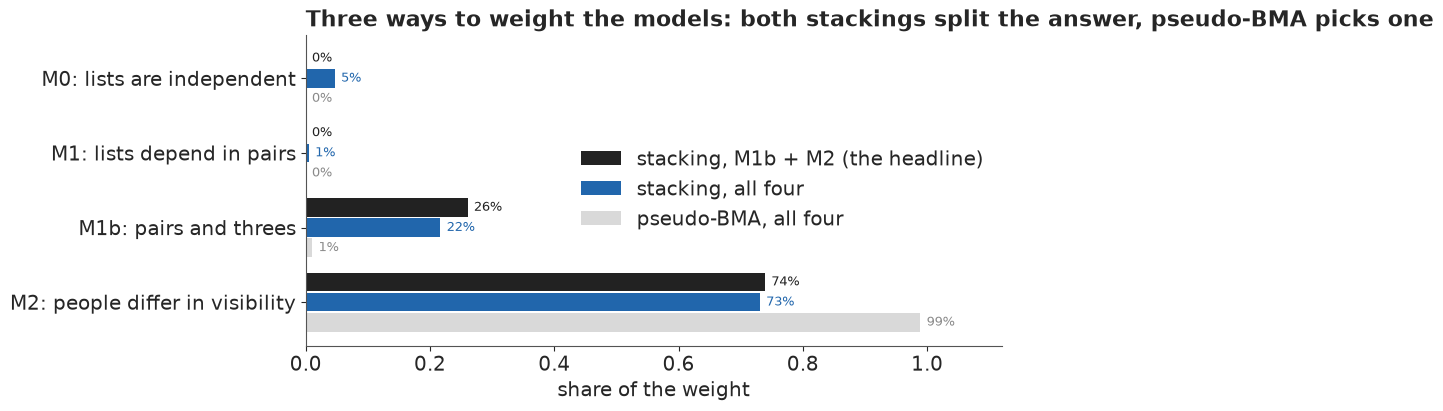

In [18]:
fig, ax = plt.subplots(figsize=(10, 4.0))
labels = ["M0: lists are independent", "M1: lists depend in pairs", "M1b: pairs and threes",
          "M2: people differ in visibility"]
y = np.arange(4)
w_head = np.zeros(4)
w_head[j2] = w2
for off, w_, col, tcol, lab in [(-0.27, w_head, INK, INK, "stacking, M1b + M2 (the headline)"),
                                (0.0, w_st, HI, HI, "stacking, all four"),
                                (0.27, w_pb, LIGHT, MUTED, "pseudo-BMA, all four")]:
    ax.barh(y + off, w_, height=0.25, color=col, label=lab)
    for yy, v in zip(y, w_):
        ax.text(v + 0.01, yy + off, f"{v:.0%}", va="center", fontsize=9.5, color=tcol)
ax.set_yticks(y, labels)
ax.invert_yaxis()
ax.set_xlim(0, 1.12)
ax.set_xlabel("share of the weight")
ax.legend(loc="center right", frameon=False)
ax.set_title("Three ways to weight the models: both stackings split the answer, pseudo-BMA picks one",
             loc="left");

### What you would have to believe

Averaging handles the dependencies the data can see. A sceptic can still ask: what if two lists
depend on each other more than the model suggests? The question has a precise answer. Take the
ABA-HRW pair, which M1b puts at an odds multiplier of about 0.8 (printed below), fix it at a
chosen value - 1, 1.5, 2, 3 or 4 times chance - and refit M1b with everything else free. One
compiled model with the fixed value in `pm.Data` serves all five fits.

ABA-HRW odds multiplier when free (M1b): median 0.81, 89% 0.59-1.01


ABA-HRW fixed at x1: divergences 0, N 9,737 (89%: 8,889-11,266)


ABA-HRW fixed at x1.5: divergences 0, N 13,550 (89%: 11,040-17,448)


ABA-HRW fixed at x2: divergences 0, N 17,430 (89%: 14,041-21,874)


ABA-HRW fixed at x3: divergences 0, N 23,082 (89%: 19,214-27,245)


ABA-HRW fixed at x4: divergences 0, N 27,144 (89%: 22,431-33,293)


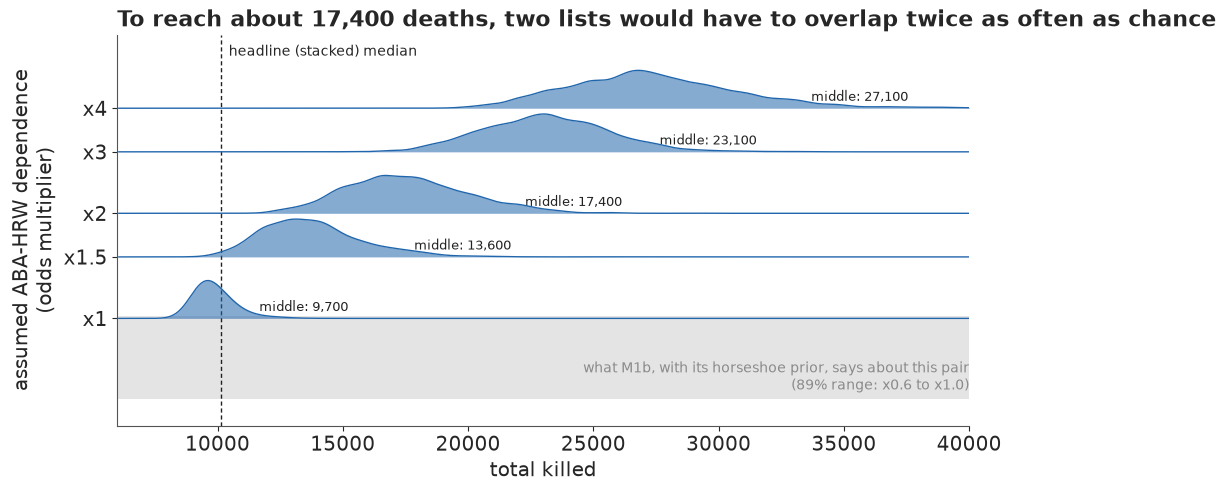

In [19]:
print("ABA-HRW odds multiplier when free (M1b): median {:.2f}, 89% {:.2f}-{:.2f}".format(
    *np.quantile(ABA_HRW_FREE, [0.5, 0.055, 0.945])))
t0 = time.time()
comp = nutpie.compile_pymc_model(loglinear(LISTS, H, n, orders=(2, 3), tau_sd=(0.5, 0.25),
                                           fix_pair=(LISTS.index("ABA"), LISTS.index("HRW"))))
SENS = {}
for mult in (1, 1.5, 2, 3, 4):
    tr = nutpie.sample(comp.with_data(fixed=np.log(mult)), chains=4, draws=500, tune=400, seed=RANDOM_SEED,
                       progress_bar=False, target_accept=0.99)
    SENS[mult] = NOBS + rng.poisson(tr.posterior["N0_mean"].to_numpy().ravel())
    q = np.quantile(SENS[mult], [0.055, 0.5, 0.945])
    print(f"ABA-HRW fixed at x{mult}: divergences {int(tr.sample_stats['diverging'].sum())}, "
          f"N {q[1]:,.0f} (89%: {q[0]:,.0f}-{q[2]:,.0f})")
TIMES["sensitivity"] = time.time() - t0


def ridgeline(ax, rows, ys, xgrid, color=HI, height=0.8):
    """Smoothed densities of each row's draws, drawn as ridges at heights ys (largest peak = height)."""
    for v, y0 in zip(rows, ys):
        h = np.histogram(v, bins=xgrid)[0].astype(float)
        k = np.exp(-0.5 * (np.arange(-12, 13) / 4) ** 2)
        h = np.convolve(h, k / k.sum(), mode="same")
        h = height * h / h.max()
        xc = 0.5 * (xgrid[1:] + xgrid[:-1])
        ax.fill_between(xc, y0, y0 + h, color=color, alpha=0.55, lw=0, zorder=3)
        ax.plot(xc, y0 + h, color=color, lw=1, zorder=4)


fig, ax = plt.subplots(figsize=(10, 4.8))
mults = list(SENS)
ys = np.log2(mults)
lo_f, hi_f = np.quantile(ABA_HRW_FREE, [0.055, 0.945])
ax.axhspan(np.log2(lo_f), np.log2(hi_f), color=LIGHT, alpha=0.7, lw=0, zorder=0)
ax.text(40_000, np.log2(lo_f) + 0.05, f"what M1b, with its horseshoe prior, says about this pair\n"
        f"(89% range: x{lo_f:.1f} to x{hi_f:.1f})", ha="right", va="bottom", fontsize=10, color=MUTED)
ridgeline(ax, [SENS[mm] for mm in mults], ys, np.arange(6000, 42000, 100), height=0.36)
for mm, y0 in zip(mults, ys):
    ax.text(np.quantile(SENS[mm], 0.945) + 400, y0 + 0.04, f"middle: {round(np.median(SENS[mm]), -2):,.0f}",
            ha="left", va="bottom", fontsize=9.5, color=INK)
ax.axvline(np.median(N_MIX), color=INK, lw=1, ls=(0, (3, 2)))
ax.text(np.median(N_MIX), ys[-1] + 0.5, "  headline (stacked) median", ha="left", fontsize=10)
ax.set_yticks(ys, [f"x{mm}" for mm in mults])
ax.set_ylabel("assumed ABA-HRW dependence\n(odds multiplier)")
ax.set_xlabel("total killed")
ax.set_xlim(6000, 40000)
ax.set_ylim(np.log2(lo_f) - 0.25, ys[-1] + 0.7)
ax.set_title(f"To reach about {round(np.median(SENS[2]), -2):,.0f} deaths, two lists would have to overlap "
             "twice as often as chance", loc="left");

Each ridge is the posterior of the total under one assumption, and they walk steadily right: about
9,700 if ABA and HRW are independent given the other lists, about 13,600 at 1.5 times chance,
17,400 at 2, 23,100 at 3 and 27,100 at 4. The grey band is where M1b puts this dependence when it
is free, 0.6 to 1.0, at or below the first row of the sweep. That band is the horseshoe's reading,
not the data's alone: under the nearly flat priors of part C the pair's 89% range runs from about
0.5 to 1.6-1.7, and to about 2.2-2.4 when the main effects are widened as well (the saturated MLE
is 1.5). Its log moves closely with $\lambda_0$ (a correlation of about 0.9), so this sweep is close
to dialling the hidden count directly. The answer to the sceptic is still concrete: a total near
17,400 needs these two lists, the ABA's refugee interviews and Human Rights Watch's investigations,
to share people twice as often as chance once the other lists are accounted for. Only the flattest
priors of part C allow that, while the sparse model says they share them slightly *less* often
than chance. That is a claim one can argue about with people who know how the lists were made,
which is the point of drawing it.

## F · Six sparse lists: modern slavery in the UK, 2013

In 2014 the Home Office published the first estimate of the number of potential victims of
modern slavery in the UK, 10,000 to 13,000, from an MSE of the National Crime Agency's 2013
assessment (Silverman 2014). The estimate was quoted in Parliament during the passage of the
Modern Slavery Act 2015. The data are 2,744 people on six lists: local authorities (LA), NGOs
(NG), police forces (PF), government organisations (GO), the general public (GP) and the
National Crime Agency (NCA). With six lists there are 63 observable histories, and only 25 of
them have anyone in them; some pairs of lists share nobody at all.

In [20]:
UK_L, UK_H, UK_n, UK_KEY = table("uk2013")
print(f"UK 2013: {UK_n.sum():,} people, {len(UK_L)} lists, {np.sum(UK_n > 0)} of {len(UK_n)} histories observed")
print("list sizes:", {l: int(UK_n[UK_H[:, k] == 1].sum()) for k, l in enumerate(UK_L)})
print("single-list counts:", {l: int(UK_n[(UK_H.sum(1) == 1) & (UK_H[:, k] == 1)][0]) for k, l in enumerate(UK_L)})
never = [f"{UK_L[a]}-{UK_L[b]}" for a, b in it.combinations(range(6), 2)
         if UK_n[(UK_H[:, a] == 1) & (UK_H[:, b] == 1)].sum() == 0]
print("pairs of lists sharing nobody:", never)
# the Home Office model: PF and NCA merged, six pair terms chosen by stepwise AIC (Silverman 2014)
L5, H5, n5, _ = table("uk2013", merge=("PF", "NCA", "PFNCA"))
ix = {l: i for i, l in enumerate(L5)}
ho_terms = [(ix[a], ix[b]) for a, b in [("LA", "NG"), ("NG", "GP"), ("PFNCA", "GP"), ("LA", "PFNCA"), ("GO", "GP"),
                                        ("NG", "GO")]]
b, N0, dev, df = fit_mle(H5, n5, ho_terms)
print(f"Home Office model refitted: total {n5.sum() + N0:,.0f} (report: 11,313), deviance {dev:.1f} on {df} df")

UK 2013: 2,744 people, 6 lists, 25 of 63 histories observed
list sizes: {'LA': 94, 'NG': 567, 'PF': 1102, 'GO': 807, 'GP': 336, 'NCA': 102}
single-list counts: {'LA': 54, 'NG': 463, 'PF': 907, 'GO': 695, 'GP': 316, 'NCA': 57}
pairs of lists sharing nobody: ['LA-GP', 'LA-NCA']
Home Office model refitted: total 11,310 (report: 11,313), deviance 16.4 on 19 df


Our refit of the Home Office model gives 11,310 against the report's 11,313, with the same
deviance (16.4 on 19 degrees of freedom); the table is the one they used. Most people are on a
single list, above all the 907 known only to police forces, the 695 known only to government
organisations and the 463 known only to NGOs, and the general public's list is small and
overlaps the others very little.

Never-overlapping pairs are a problem for classical fitting: the maximum-likelihood pair term
goes to minus infinity, which analysts handle by deleting it from the model (Chan, Silverman &
Vincent 2021 work through the consequences). The horseshoe handles them without a decision: a
pair with no shared people gets a negative but finite term, kept from running away by its prior.
We fit the pairwise horseshoe model and the latent-class model, first on all six lists and then
on Silverman's (2020) four-list version, which drops the general-public list and merges the police
forces with the National Crime Agency (2,428 people). On these sparse data the latent-class model
uses $C = 5$ classes, LCMCR's default.

In [21]:
t0 = time.time()
UK = {}
for label, kw in [("six lists", {}), ("four lists", dict(drop=("GP",), merge=("PF", "NCA", "PFNCA")))]:
    Lx, Hx, nx, kx = table("uk2013", **kw)
    KEYS = kx
    idata, sec = fit(loglinear(Lx, Hx, nx, orders=(2,), tau_sd=(0.5,)), 0.99)
    UK[f"log-linear, {label}"] = summarise(f"log-linear, {label}", idata, nx, sec)
    if label == "six lists":
        lam2 = idata.posterior["lam2"].median(("chain", "draw")).to_series()
        print("   pair terms for never-overlapping pairs (posterior median):",
              {t: round(float(lam2[t]), 1) for t in never})
    del idata
    idata, sec = fit(latent_class(Lx, Hx, nx, C=5), 0.99, tune=1000)
    UK[f"latent class, {label}"] = summarise(f"latent class, {label}", idata, nx, sec, skip=("q", "w", "mu"))
    print("   per-chain median total:", np.round(nx.sum() + np.median(idata.posterior["N0_mean"].to_numpy(), axis=1), -2))
    del idata
KEYS = KEY
TIMES["UK fits"] = time.time() - t0
for k, out in UK.items():
    print(f"{k:28s} N 5.5/50/94.5/99.5%: {np.round(np.quantile(out['N'], [0.055, 0.5, 0.945, 0.995]), -1)}")

log-linear, six lists: 3 s, tune 400, divergences 0, r_hat(N0) 1.008, worst r_hat 1.009 (lk), ESS(N0) 345
   total N: 10,333  (89%: 8,210-13,058);  cells outside their 89% predictive range: 0 of 63  []


   PSIS-LOO: 15 of 63 cells with Pareto k > 0.7
   pair terms for never-overlapping pairs (posterior median): {'LA-GP': -1.0, 'LA-NCA': -0.4}


latent class, six lists: 17 s, tune 1000, divergences 0, r_hat(N0) 1.028, worst r_hat 1.665 (alpha), ESS(N0) 607
   total N: 21,840  (89%: 16,747-30,152);  cells outside their 89% predictive range: 1 of 63  [('010010', 1, 2, 12)]


   PSIS-LOO: 16 of 63 cells with Pareto k > 0.7
   per-chain median total: [22800. 21500. 22400. 20800.]


log-linear, four lists: 4 s, tune 400, divergences 0, r_hat(N0) 1.007, worst r_hat 1.008 (mu), ESS(N0) 435
   total N: 9,761  (89%: 6,826-12,285);  cells outside their 89% predictive range: 0 of 15  []


   PSIS-LOO: 10 of 15 cells with Pareto k > 0.7


latent class, four lists: 12 s, tune 1000, divergences 0, r_hat(N0) 1.005, worst r_hat 1.087 (alpha), ESS(N0) 969
   total N: 12,037  (89%: 10,563-13,924);  cells outside their 89% predictive range: 1 of 15  [('0101', 19, 20, 43)]


   PSIS-LOO: 8 of 15 cells with Pareto k > 0.7
   per-chain median total: [12100. 12100. 12100. 11900.]
log-linear, six lists        N 5.5/50/94.5/99.5%: [ 8210. 10330. 13060. 15490.]
latent class, six lists      N 5.5/50/94.5/99.5%: [16750. 21840. 30150. 38130.]
log-linear, four lists       N 5.5/50/94.5/99.5%: [ 6830.  9760. 12290. 14470.]
latent class, four lists     N 5.5/50/94.5/99.5%: [10560. 12040. 13920. 15640.]


On all six lists the two models disagree by a factor of two. The pairwise horseshoe says about
10,300 (89%: about 8,200-13,100), in line with the Home Office's 10,000-13,000. The latent-class
model says about 22,000 (89%: 17,000-30,000), and its tail is long: the 99.5% point is near
38,000. Both reproduce the observed cells (the latent-class model misses one, a single person
whose history it expects to be a little more common). The two never-overlapping pairs got
modestly negative terms, about -1.0 and -0.4 (odds multipliers of about 0.4 and 0.7), without
anyone deleting them: pairs that involve the small LA list (94 people) and share nobody are only
weak evidence that the lists avoid each other, and where the MLE would send the terms to minus
infinity, the prior keeps them finite. Silverman (2020) found the same split: LCMCR gave a median
of 23,000 (95%: 17,200-34,200), against log-linear answers near 11,000-12,000.

On the four-list table the two models come much closer: about 9,800 against 12,000. Silverman got
11,400 from Madigan & York's averaging and 12,000 from LCMCR on the same table. The doubling comes
from one list, 336 people of whom 316 are on no other list. To a latent-class model, a list that
shares almost nobody looks like evidence of a large class of people whom the other five lists
hardly reach; to a pairwise log-linear model it is a list with strong negative dependencies on the
rest. The data cannot say which story is right, because both fit every cell.

The latent-class fit mixes less well on six lists than on Kosovo: its hidden count has r_hat 1.03
and the chains' medians differ by up to a tenth, while $\alpha$ reaches r_hat 1.7 (how many
near-empty classes there are is barely identified), so the 22,000 is good to about a thousand. On four lists the hidden count's
r_hat is 1.005 and the chains agree to within 2%, though $\alpha$ still has r_hat 1.09. The tools of part E do not settle the question either: a latent-class model
explains the large single-list cells with classes of their own, so leaving one of them out leaves
that class unidentified. For the UK, the honest summary is the comparison itself: one list doubles
the answer, and the choice between the models is a judgement about how that list was made.

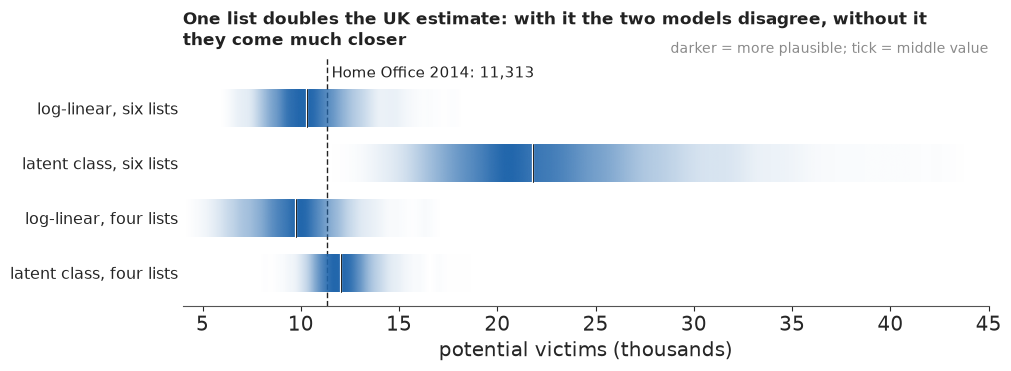

In [22]:
fig, ax = plt.subplots(figsize=(10, 3.6))
pub.gradient_intervals(ax, [out["N"] / 1000 for out in UK.values()], list(UK), xlim=(4, 45), ref=11.313,
                       ref_label="Home Office 2014: 11,313", xlabel="potential victims (thousands)",
                       title="One list doubles the UK estimate: with it the two models disagree, "
                             "without it they come much closer");

## G · Explaining it to everyone

A statistician summarising part E would draw something like the figure below: the posterior of
the total under each model, as points with 89% intervals, against the published estimate.

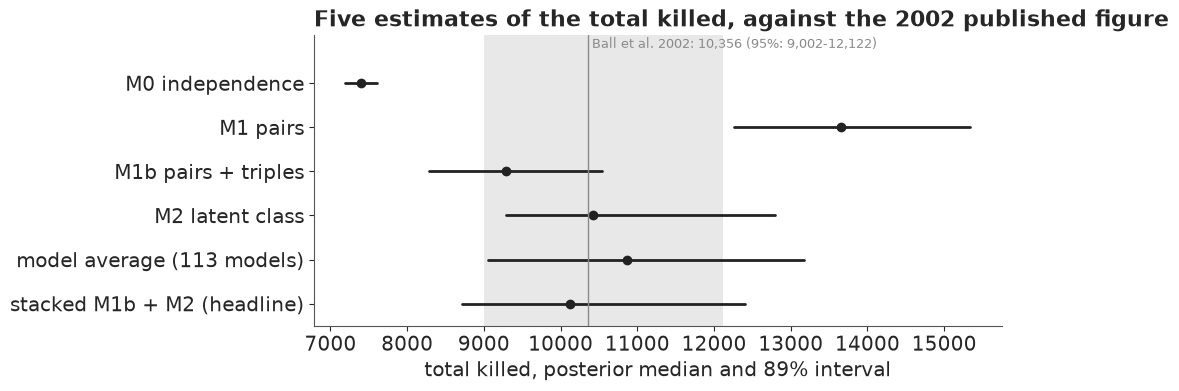

In [23]:
fig, ax = plt.subplots(figsize=(10, 3.8))
rows = [(k, v["N"]) for k, v in KOS.items()] + [("model average (113 models)", BMA[1.0]),
                                                ("stacked M1b + M2 (headline)", N_MIX)]
for i, (k, v) in enumerate(rows):
    lo, mid, hi = np.quantile(v, [0.055, 0.5, 0.945])
    ax.plot([lo, hi], [i, i], color=INK, lw=2)
    ax.plot(mid, i, "o", color=INK)
ax.axvspan(9002, 12122, color=LIGHT, alpha=0.6, lw=0)
ax.axvline(10356, color=MUTED, lw=1)
ax.text(10356, -0.8, " Ball et al. 2002: 10,356 (95%: 9,002-12,122)", fontsize=9.5, color=MUTED)
ax.set_yticks(range(len(rows)), [r[0] for r in rows])
ax.set_ylim(len(rows) - 0.5, -1.1)
ax.set_xlabel("total killed, posterior median and 89% interval")
ax.set_title("Five estimates of the total killed, against the 2002 published figure", loc="left");

It is the right figure for a reader who knows what a posterior interval is. For anyone else it
has three problems. It shows the total, so the 4,400 people who were named - the part nobody
disputes - disappear into the scale, and with them the size of what was missed relative to what
was seen. Its intervals have hard ends, which readers take as limits (Correll & Gleicher 2014).
And it is a chart of models, when the reader's question is about people.

### The iceberg

The headline display is an **icon array**: one square per 50 people, the 4,400 people on a list
above a waterline and the people on no list below it. Icon arrays help readers of every level of
numeracy understand risks and proportions (Galesic, Garcia-Retamero & Gigerenzer 2009), and counts
of people - natural frequencies - are understood better than percentages (the Cochrane review of
Akl et al. 2011). Uncertainty is drawn in the squares themselves: the hidden squares are solid up
to the posterior's 5.5% point (very likely at least this many: about 19 worlds in 20), hatched up
to the 94.5% point (somewhere in here), and a dotted outline marks the 97.5% point, so the long
tail is visible without dominating. Squares fill in reading order, which is easier to count than
scattered icons. Beside it a **quantile dotplot** gives the precise version: 50 dots, each one an
equally likely hidden count; quantile dotplots gave less variable probability judgments than
densities (Kay, Kola, Hullman & Munson 2016) and better decisions under uncertainty (Fernandes et
al. 2018). The title states the finding in natural frequencies, with the denominator used
throughout: per 10 people on a list.

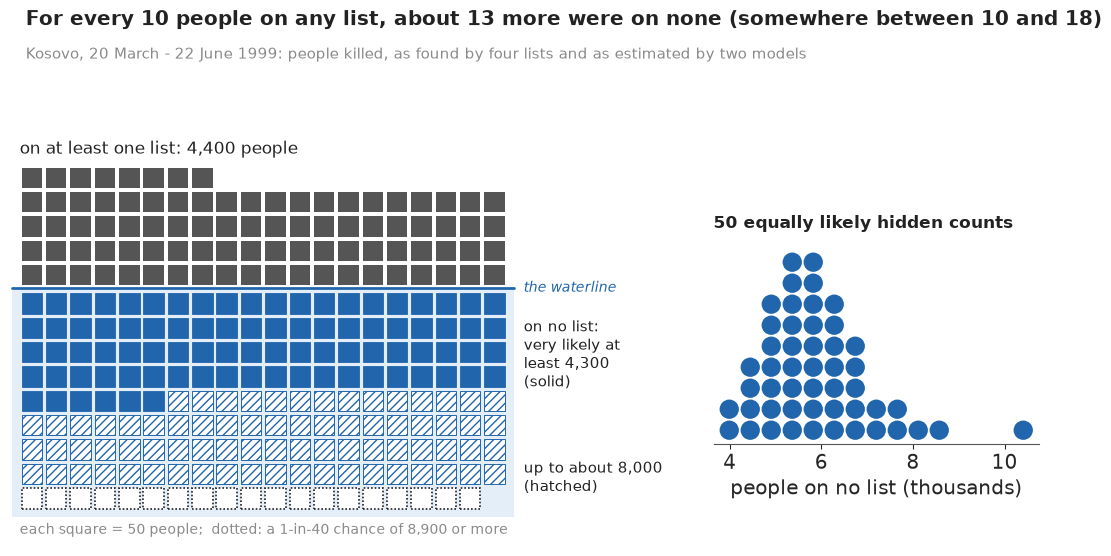

In [24]:
UNIT, NCOL, WATER = 50, 20, "#e4eef8"


def iceberg(ax, nobs, hidden, unit=UNIT, ncol=NCOL, hop=None, depth=None):
    """Icon array of listed (above a waterline) and unlisted (below) people, one square per `unit`.
    Below the line: solid to the 5.5% point, hatched to 94.5%, dotted outline to 97.5%. With `hop` (one
    possible hidden count) the squares are solid up to it and a bracket marks the 89% range."""
    lo, hi, tail = np.quantile(hidden, [0.055, 0.945, 0.975])
    k_obs = int(round(nobs / unit))
    r_obs = int(np.ceil(k_obs / ncol))
    n_lo, n_hi, n_tail = (int(round(v / unit)) for v in (lo, hi, tail))
    depth = depth or int(np.ceil(n_tail / ncol))
    s = 0.84
    for i in range(k_obs):  # the tip: fill from the waterline up, the part row on top
        r, c = divmod(i, ncol)
        ax.add_patch(Rectangle((c + 0.08, r + 0.2), s, s, fc=GREY, ec="none"))
    ax.add_patch(Rectangle((-0.3, -depth - 0.3), ncol + 0.6, depth + 0.3, fc=WATER, ec="none", zorder=0))
    ax.plot([-0.3, ncol + 0.3], [0.08, 0.08], color=HI, lw=2)
    k_hop = None if hop is None else int(round(hop / unit))
    for i in range(n_tail if hop is None else k_hop):
        r, c = divmod(i, ncol)
        x, y = c + 0.08, -(r + 1) + 0.04
        if hop is not None or i < n_lo:
            ax.add_patch(Rectangle((x, y), s, s, fc=HI, ec=HI, lw=0.6))
        elif i < n_hi:
            ax.add_patch(Rectangle((x, y), s, s, fc="white", ec=HI, hatch="////", lw=0.7))
        else:
            ax.add_patch(Rectangle((x, y), s, s, fc="white", ec=INK, ls=(0, (1, 1.2)), lw=1.2))
    xl = ncol + 0.7
    ax.text(0, r_obs + 0.45, f"on at least one list: {nobs:,} people", fontsize=12, color=INK, va="bottom")
    ax.text(xl, 0.1, "the waterline", fontsize=10, color=HI, va="center", style="italic")
    if hop is None:
        rnd = lambda v: f"{round(v, -2):,.0f}"
        ax.text(xl, -(n_lo / ncol) / 2 - 0.5, f"on no list:\nvery likely at\nleast {rnd(lo)}\n(solid)",
                fontsize=11, color=INK, va="center")
        ax.text(xl, -n_hi / ncol + 0.3, f"up to about {rnd(hi)}\n(hatched)", fontsize=11, color=INK, va="center")
        ax.text(0, -depth - 0.55, f"each square = {unit} people;  dotted: a 1-in-40 chance of {rnd(tail)} or more",
                fontsize=10, color=MUTED, va="top")
    else:
        ax.annotate("", (xl - 0.25, -n_lo / ncol), (xl - 0.25, -n_hi / ncol),
                    arrowprops=dict(arrowstyle="|-|", color=MUTED, lw=1, mutation_scale=4))
        ax.text(xl, -min(k_hop, ncol * depth) / ncol + 0.2, f"this world:\n{round(hop, -2):,.0f} on no list",
                fontsize=11.5, color=INK, va="top", weight="bold")
        ax.text(0, -depth - 0.55, f"each square = {unit} people;  bracket: 9 worlds in 10 end in this band",
                fontsize=10, color=MUTED, va="top")
    ax.set_xlim(-0.4, ncol + 7.2)
    ax.set_ylim(-depth - 1.5, r_obs + 1.3)
    ax.set_aspect("equal")
    ax.axis("off")


HEAD_TITLE = (f"For every 10 people on any list, about {per10[1]:.0f} more were on none "
              f"(somewhere between {per10[0]:.0f} and {per10[2]:.0f})")
fig_ice = plt.figure(figsize=(10.5, 6.2), layout="none")
fig_ice.text(0.015, 0.965, HEAD_TITLE, fontsize=14.5, color=INK, va="top", weight="bold")
fig_ice.text(0.015, 0.905, "Kosovo, 20 March - 22 June 1999: people killed, as found by four lists and as "
             "estimated by two models", fontsize=11, color=MUTED, va="top")
iceberg(fig_ice.add_axes([0.0, 0.0, 0.64, 0.86]), NOBS, HID)
pub.quantile_dotplot(fig_ice.add_axes([0.67, 0.22, 0.31, 0.42]), HID / 1000, n=50,
                     xlabel="people on no list (thousands)", title="50 equally likely hidden counts")
HEADLINE.update(fig_ice)

The picture makes the main point before anyone reads a number: the part below the waterline is
bigger than the part above it. The solid squares are the hidden people the models make very
likely (about 4,300, the same floor as the plain-words sentence), the hatched ones the range they
leave open (up to about 8,000). The figure also sits at the top of the notebook, as the
plain-words headline.

It has pitfalls of its own. Rounding to 50-person squares hides anything smaller. A reader may
take the hatched squares as "maybe" and ignore them, or the dotted ones as impossible; the
dotplot beside it is there to show that every one of those counts is a real possibility. And an
iceberg suggests a fixed mass under the water, when the models only say "somewhere between". The
animation below addresses that last point.

### Possible worlds, one at a time

A **hypothetical outcome plot** (HOP) shows the uncertainty as change: each frame is one
possible world, an equally likely hidden count, and the submerged part redraws from frame to
frame. HOPs help untrained readers judge how reliable a difference or trend is better than error
bars (Hullman, Resnick & Adar 2015; Kale, Nguyen, Kay & Hullman 2019). The 40 worlds are
quantiles of the posterior, shown in a shuffled order, at half a second a frame, slow enough to
count and below the three flashes a second that accessibility guidance forbids.

wrote E109_counting_the_uncounted_iceberg.gif: 40 frames, 576x460 px, 0.3 MB
hidden count in the 40 worlds: 3,857 to 9,933, median 5,728


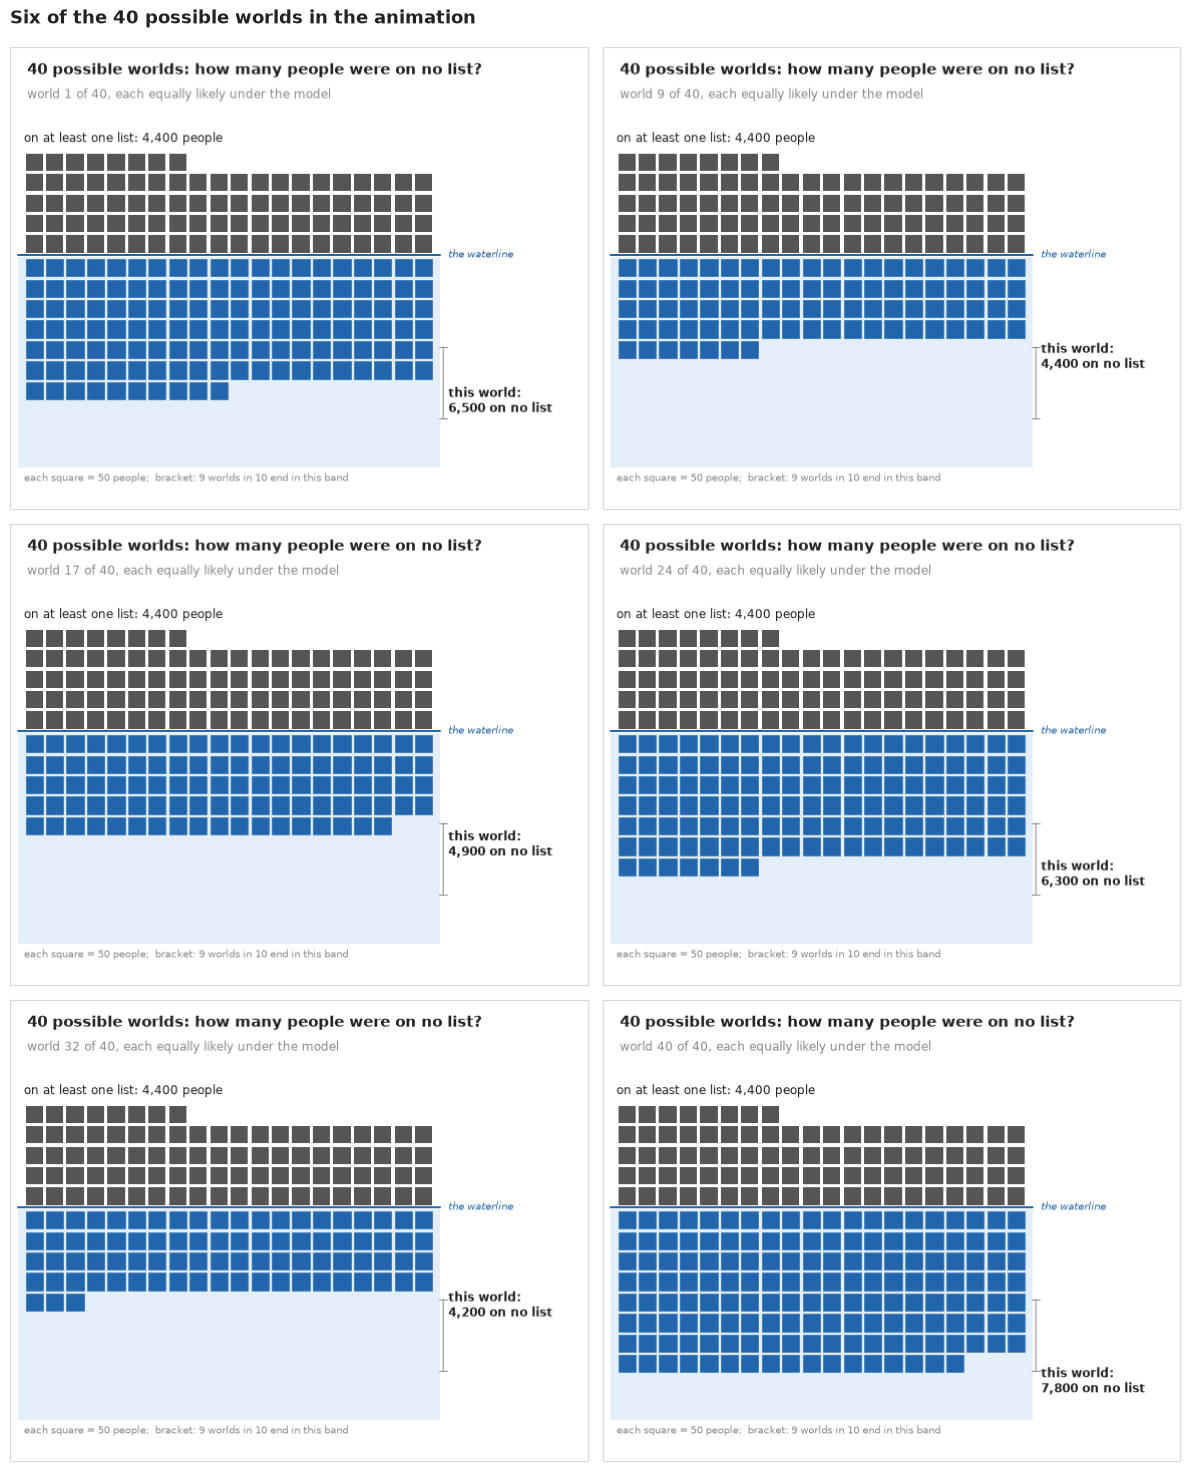

In [25]:
NB_STEM = "E109_counting_the_uncounted"
GIF = f"{NB_STEM}_iceberg.gif"  # written next to the notebook: the site copies every {stem}*.gif
q40 = np.quantile(HID, (np.arange(40) + 0.5) / 40)
order40 = np.random.default_rng(5).permutation(40)
depth = int(np.ceil(max(q40.max(), np.quantile(HID, 0.975)) / UNIT / NCOL))
fig_hop = plt.figure(figsize=(8, 6.4), dpi=72, layout="none")
ax_hop = fig_hop.add_axes([0.01, 0.0, 0.98, 0.86])


def hop_frame(k):
    ax_hop.clear()
    iceberg(ax_hop, NOBS, HID, hop=q40[order40[k]], depth=depth)
    fig_hop.texts.clear()
    fig_hop.text(0.03, 0.965, "40 possible worlds: how many people were on no list?", fontsize=15, color=INK,
                 va="top", weight="bold")
    fig_hop.text(0.03, 0.91, f"world {k + 1} of 40, each equally likely under the model", fontsize=11.5,
                 color=MUTED, va="top")


t0 = time.time()
frames = pub.save_gif(fig_hop, hop_frame, 40, GIF, ms=500, first_ms=1500, last_ms=1500)
plt.close(fig_hop)
print(f"hidden count in the 40 worlds: {q40.min():,.0f} to {q40.max():,.0f}, median {np.median(HID):,.0f}")
TIMES["GIF"] = time.time() - t0
pub.gif_contact_sheet(frames, title="Six of the 40 possible worlds in the animation");

The animation is saved as
[E109_counting_the_uncounted_iceberg.gif](E109_counting_the_uncounted_iceberg.gif), ready for a
slide or a message; the six frames above are its static companion for print and screen readers.

![Animated icon array: 88 grey squares above a waterline stand for the 4,400 people on a list;
below it, blue squares for the people on no list change from frame to frame, from about 3,900
to about 9,900, most often near 5,700](E109_counting_the_uncounted_iceberg.gif)

### The column nobody can see

Part A drew the overlaps with a question mark where the people on no list belong. Filling that
column with 20 equally likely values of the hidden count turns the same chart into the answer:
the one history nobody observed is larger than any history somebody did.

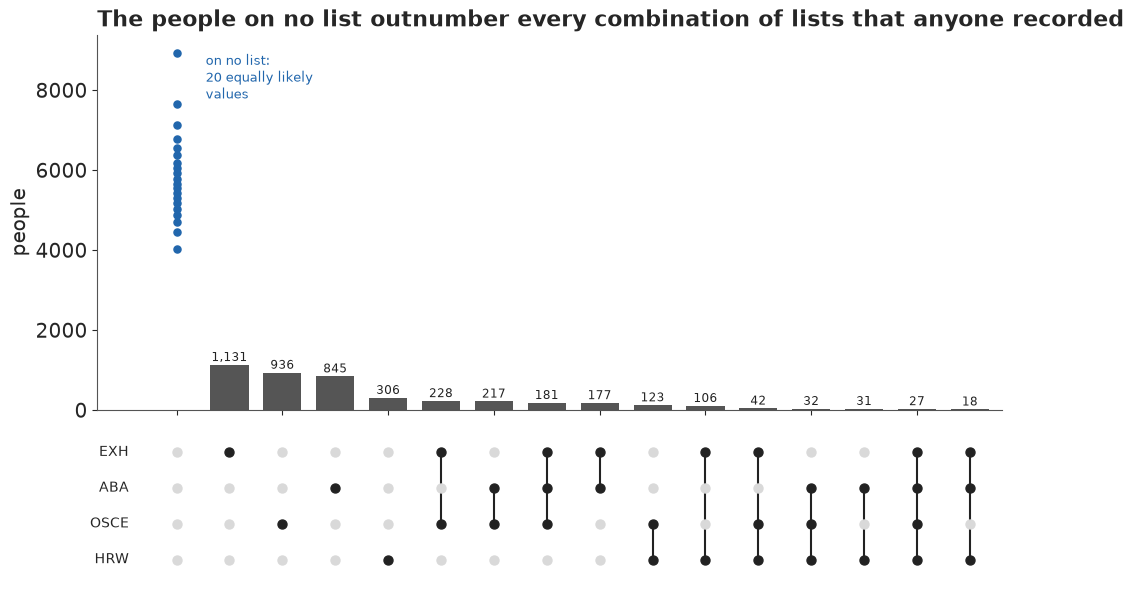

In [26]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(10, 5.8), sharex=True, gridspec_kw={"height_ratios": [3, 1.2]})
overlap_chart(a1, a2, hidden=HID,
              title="The people on no list outnumber every combination of lists that anyone recorded")
a1.set_xlim(-1.5, len(n) + 0.6);

### A hundred possible totals

For readers who want the total and the published figure together, the **swarm** draws 100
possible worlds as 100 dots, each the total number of people killed in one world. FiveThirtyEight
used this design for its 2020 election forecast ("100 representative outcomes"), and the counting
it invites is the same as in the dotplot. The 100 worlds are quantiles, not a random 100, so a
rerun does not change the count by several dots.

worlds above 10,356: 41 of 100; inside 9,002-12,122: 83; all 100 between 7,973 and 15,409


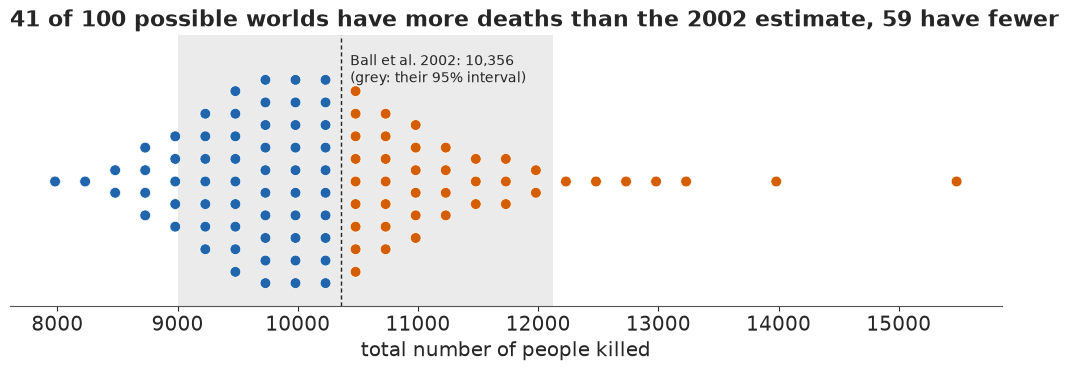

In [27]:
q100 = np.quantile(N_MIX, (np.arange(100) + 0.5) / 100)
binw = 250
xs = 10356 + (np.floor((q100 - 10356) / binw) + 0.5) * binw  # no column straddles the reference
ys = np.zeros(100)
for v in np.unique(xs):
    mk_ = xs == v
    ys[mk_] = np.arange(mk_.sum()) - (mk_.sum() - 1) / 2
above = q100 > 10356
fig, ax = plt.subplots(figsize=(10, 3.6))
ax.axvspan(9002, 12122, color=LIGHT, alpha=0.5, lw=0, zorder=0)
ax.scatter(xs, ys, s=60, color=np.where(above, LO, HI), edgecolor="white", lw=0.5, zorder=3)
ax.axvline(10356, color=INK, lw=1, ls=(0, (3, 2)))
ax.text(10356 + 80, ys.max() + 1.2, "Ball et al. 2002: 10,356\n(grey: their 95% interval)", fontsize=10,
        va="top")
ax.set_ylim(ys.min() - 1, ys.max() + 2)
ax.set_yticks([])
ax.set_xlabel("total number of people killed")
ax.set_title(f"{above.sum()} of 100 possible worlds have more deaths than the 2002 estimate, "
             f"{100 - above.sum()} have fewer", loc="left")
for s_ in ("left", "right", "top"):
    ax.spines[s_].set_visible(False)
inside = ((q100 >= 9002) & (q100 <= 12122)).sum()
print(f"worlds above 10,356: {above.sum()} of 100; inside 9,002-12,122: {inside}; "
      f"all 100 between {q100.min():,.0f} and {q100.max():,.0f}")

About four in ten worlds lie above the published estimate and the rest below, and about four in
five lie inside its interval: two analyses by different routes, decades apart, agree.

### What the public version gains, and what it costs

Set the iceberg beside the forest plot. The forest plot answers "which model says what", which
matters to analysts and is where disagreements are argued. The iceberg answers "how many people
were missed, compared with those we know about", in people, with the known and the unknown in
the same units and the uncertainty in the marks rather than in whiskers. The swarm and the
column chart answer the two follow-up questions, "is that consistent with what was published?"
and "how does the missing group compare with the groups we did see?". What the public versions
give up is the models: none of them says that the answer depends on an assumption about how the
lists depend on each other. That is why the plain-words block carries a separate confidence
statement, and why the ridgeline of part E, which shows that dependence directly, belongs in any
briefing for people who will act on the number.

### These are people

Each square in these figures is fifty people who were killed, most of them civilians, and the
hidden squares are people whose deaths no organisation recorded. Ball et al.'s estimates were
part of the evidence that the pattern of killings followed the movements of Yugoslav forces
rather than NATO bombing or KLA activity; the UK estimate informed the strategy behind the Modern
Slavery Act 2015, and the Home Office called its own result tentative. Numbers like these are
used in courts and parliaments, which is the strongest reason to show their uncertainty in a
form people can read, and to say plainly which assumptions they rest on.

In [28]:
TIMES["total"] = time.time() - T_START
print({k: round(v) for k, v in TIMES.items()})

{'log-linear fits': 9, 'prior families': 31, 'latent class fit': 9, 'BMA': 0, 'exact LOO': 76, 'sensitivity': 10, 'UK fits': 37, 'GIF': 6, 'total': 195}


## Summary

- **Overlap measures the unseen only through an assumption.** Two lists with the same sizes gave
  Lincoln-Petersen estimates of about 7,500, 10,000 or 15,000 for a population of 10,000,
  depending only on how the lists depended on each other. The six Kosovo pairs gave 5,500-9,700,
  all below the final estimate: positive dependence, as Ball et al. (2002) concluded.
- **Log-linear models need the three-way term, and the prior family decides the answer.**
  Independence (about 7,400) and pairwise (about 13,600) models missed 10 and 5 of the 15 cells;
  the saturated model with three-way terms fits every cell by construction and gave about 9,300
  (89%: 8,300-10,500) under the horseshoe. The plain horseshoe gave about ninety divergences, and
  about ten at `target_accept=0.99`; the regularised one gave none even at the default. Nearly
  flat interaction priors gave about 11,200-11,500, and about 14,000-15,000 once the main effects
  were widened too, against the saturated MLE of 17,000; under the horseshoe the main-effect and
  intercept priors barely mattered. The limit: which prior is right is a judgement, not a result.
- **A latent-class model reached the published answer by another route**: about 10,400 (89%:
  9,300-12,800) against Ball et al.'s 10,356. Its class parameters had r_hat up to about 1.3 from
  label switching while the hidden count had 1.00. With ten classes it fits every cell easily, so
  the fit is no test of it.
- **Averaging over models depends on how you average.** Model averaging over 113 hierarchical
  log-linear models gave about 10,900 (89%: 9,100-13,200), moving from 10,000 to 11,200 with the
  interaction prior; Silverman's (2020) run of Madigan & York's method gave 12,600. PSIS-LOO was
  unreliable in most cells, so stacking used 60 exact refits; it split the weight between M1b and
  M2 (about 1:3), while pseudo-BMA gave almost all of it to M2, and both are noisy at this size.
- **About 13 on no list for every 10 listed.** Stacking M1b and M2, which lead the others by over
  160 nats (a restriction chosen after the checks), gives a total near 10,100 (89%: 8,700-12,400)
  and makes it very likely (95%) that at least 4,300 were on no list, though M1b alone makes that
  only likely (83%). It rests on the dependence between lists that the four lists can only partly
  check.
- **The sensitivity has a price tag.** Fixing the ABA-HRW dependence at 1, 1.5, 2, 3 and 4 times
  chance moved the total from about 9,700 to 27,000; M1b puts it at 0.6-1.0, and the flattest
  priors at up to about 2.4.
- **On six sparse UK lists the answer doubles with one list.** The Home Office model refitted to
  11,310; the pairwise horseshoe gave about 10,300, the latent-class model about 22,000 with a
  99.5% point near 38,000, matching Silverman (2020), though its chains differ by up to a tenth.
  On Silverman's four-list table (no general-public list) they gave about 9,800 and 12,000.
  Neither check nor weight settles which is right.
- **The public figures count people.** An iceberg icon array with solid, hatched and dotted
  squares, a 50-dot quantile dotplot, a 40-frame HOP GIF, a dotplot column in the overlap chart
  and a 100-world swarm; what they leave out is the dependence assumption, which the confidence
  statement and the ridgeline carry.

## Try it yourself

1. **The Netherlands.** The same file holds the Dutch data (`netherlands`, 24 observed
   histories, 8,234 identified victims of trafficking, 2010-2015, analysed by van Dijk, Cruyff,
   van der Heijden & Kragten-Heerdink 2017 for the UNODC and the Dutch National Rapporteur). Fit
   the pairwise horseshoe and the latent-class model with `table("netherlands")` and compare
   them with Silverman (2020, Tables 8 and 12), where LCMCR gives about 150,000 on six lists and
   49,000 on five. Do the models disagree as much as on the UK data, and is one list responsible?
   Drop each list in turn with `table(..., drop=(...,))` and see which one moves the
   latent-class answer most.
2. **Stratify Kosovo as Ball et al. did.** Their 10,356 came from separate estimates by period
   and region. Without person-level data you cannot stratify the table, but you can see what
   heterogeneity does: simulate two strata with the latent-class model's fitted capture
   probabilities, fit the pooled four-list table with M1b, and measure how far pooling moves the
   estimate when the strata differ in size and visibility.
3. **Put the dependence in the prior, not in a sweep.** Replace the fixed ABA-HRW value in part
   E with an informative prior, for example a log odds ratio of $N(\log 1.5, 0.3)$ for "the ABA
   referred families to HRW", and refit M1b. How much does the headline move, and how does the
   posterior of that pair compare with its prior - does the data push back?